# **1. VAEP and Synergy VAEP**

This notebook values every action with **VAEP** (*Valuing Actions by Estimating Probabilities*) and, from it, measures the **synergy** between pairs of teammates: how much the pair produces together compared with the windows in which the partner is replaced by a real proxy.

| step | input | result |
|---|---|---|
| VAEP | StatsBomb on-ball events | `vaep_actions.parquet` |
| presence | line-ups and substitutions | segments with the players on the pitch |
| aggregation | VAEP and minutes | rankings by player, team, and league |
| profiles | events by player | 14 × 10 spatial matrix and PCA |
| proxy | absences of each partner | real substitute or most similar starter |
| synergy | together and proxy samples | directed offensive and defensive synergies |
| figures | rankings and VAEP summaries | PNG files in `viz/` |

Synergy is based on a real absence proxy. For each pair (A, B) of the same team:

- **Together**: minutes in which A and B were on the pitch at the same time.
- **Proxy of B**: in the matches in which B was off the pitch, the real occupant of the same substitution slot or the most spatially similar starter.

**Synergy score:** `VAEP90(A+B together) − VAEP90(A+proxy of B)`

In [1]:
import ast
import warnings
from collections import defaultdict
from pathlib import Path

from IPython.display import display

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from xgboost import XGBClassifier

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 200)

### **1.1. Configuration**

The project root is detected automatically. The combined collection tables are read from `data/raw/combined/`; products are written to `data/processed/` and figures to `viz/`. `HORIZON` sets the number of future actions used in the labels, the dimensions convert the StatsBomb pitch (120 × 80) to metres (105 × 68), and `XGB_PARAMS` configures the two classifiers.

In [2]:
# The project root is detected automatically, inside or outside `notebooks/`.
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH        = PROJECT_ROOT / 'data'
PROCESSED_PATH   = DATA_PATH / 'processed'
VIZ_PATH         = PROJECT_ROOT / 'viz'
EVENTS_PATH      = DATA_PATH / 'raw' / 'combined' / 'all_events_combined.parquet'
MATCHES_PATH     = DATA_PATH / 'raw' / 'combined' / 'all_matches_combined.parquet'
PROCESSED_PATH.mkdir(parents=True, exist_ok=True)
VIZ_PATH.mkdir(parents=True, exist_ok=True)

HORIZON          = 10
RANDOM_STATE     = 42

SB_FIELD_LENGTH  = 120.0
SB_FIELD_WIDTH   = 80.0
PITCH_LENGTH     = 105.0
PITCH_WIDTH      = 68.0

XGB_PARAMS = dict(
    objective='binary:logistic',
    eval_metric='logloss',
    tree_method='hist',
    enable_categorical=True,
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    min_child_weight=25,
    reg_lambda=2.0,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

PROJECT_ROOT

PosixPath('/Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP')

## **2. Data loading**

Only the columns used in the analysis are read. Events are sorted in time and receive `event_minute`, the continuous minute of each action.

In [3]:
event_cols = [
    'id', 'match_id', 'period', 'minute', 'second', 'timestamp', 'index',
    'type', 'team', 'team_id', 'player', 'player_id', 'position',
    'location_x', 'location_y', 'pass_end_location_x', 'pass_end_location_y',
    'carry_end_location_x', 'carry_end_location_y', 'shot_end_location',
    'pass_outcome', 'dribble_outcome', 'shot_outcome', 'ball_recovery_recovery_failure',
    'substitution_replacement', 'substitution_replacement_id', 'tactics',
]
match_cols = ['match_id', 'home_team', 'away_team', 'season', 'match_date', 'competition']

if not EVENTS_PATH.exists() or not MATCHES_PATH.exists():
    raise FileNotFoundError('Run 00-data_collection.ipynb before this notebook.')

events = pd.read_parquet(EVENTS_PATH, columns=event_cols)
matches = pd.read_parquet(MATCHES_PATH, columns=match_cols)

events = events.sort_values(['match_id', 'period', 'minute', 'second', 'index']).reset_index(drop=True)
events['event_minute'] = events['minute'].astype(float) + events['second'].fillna(0).astype(float) / 60.0

print(f'Events: {len(events):,}  |  Matches: {len(matches):,}')

Events: 5,321,459  |  Matches: 1,517


## **3. StatsBomb actions for VAEP**

VAEP uses only five StatsBomb on-ball events: `Pass`, `Carry`, `Dribble`, `Shot`, and `Ball Recovery`. The representation is deliberately minimal: action type, result when available, start location, and end location when available.

In [4]:
VAEP_EVENT_TYPES = {'Pass', 'Carry', 'Dribble', 'Shot', 'Ball Recovery'}
TYPE_NAME_BY_EVENT = {
    'Pass': 'pass',
    'Carry': 'carry',
    'Dribble': 'dribble',
    'Shot': 'shot',
    'Ball Recovery': 'ball_recovery',
}


def _scale_x(s):
    return pd.to_numeric(s, errors='coerce') * PITCH_LENGTH / SB_FIELD_LENGTH


def _scale_y(s):
    return PITCH_WIDTH - (pd.to_numeric(s, errors='coerce') * PITCH_WIDTH / SB_FIELD_WIDTH)


def _list_item(value, pos):
    if isinstance(value, (list, tuple, np.ndarray)) and len(value) > pos:
        return value[pos]
    return np.nan


def _truthy_series(s):
    return s.eq(True) | s.astype('string').str.lower().eq('true')


def add_match_team_ids(matches_df, events_df):
    team_lk = (
        events_df.dropna(subset=['match_id', 'team_id', 'team'])
        .assign(team_id=lambda d: d['team_id'].astype(int))
        .drop_duplicates(['match_id', 'team'])
        .set_index(['match_id', 'team'])['team_id']
        .to_dict()
    )
    team_ids_by_match = (
        events_df.dropna(subset=['match_id', 'team_id'])
        .assign(team_id=lambda d: d['team_id'].astype(int))
        .groupby('match_id')['team_id']
        .agg(lambda x: tuple(pd.unique(x)))
        .to_dict()
    )
    mt = matches_df.copy()
    mt['home_team_id'] = [team_lk.get((r.match_id, r.home_team)) for r in mt.itertuples(index=False)]
    mt['away_team_id'] = [team_lk.get((r.match_id, r.away_team)) for r in mt.itertuples(index=False)]
    for idx, row in mt.loc[mt['home_team_id'].isna() | mt['away_team_id'].isna()].iterrows():
        ids = team_ids_by_match.get(row['match_id'], ())
        if len(ids) == 2:
            if pd.isna(row['home_team_id']):
                mt.at[idx, 'home_team_id'] = ids[0]
            if pd.isna(row['away_team_id']):
                mt.at[idx, 'away_team_id'] = ids[1] if ids[0] == mt.at[idx, 'home_team_id'] else ids[0]
    mt['home_team_id'] = mt['home_team_id'].astype('Int64')
    mt['away_team_id'] = mt['away_team_id'].astype('Int64')
    return mt


def build_vaep_actions(ev, mt):
    match_meta = add_match_team_ids(mt, ev)
    actions = ev.loc[ev['team_id'].notna() & ev['type'].isin(VAEP_EVENT_TYPES)].copy()
    actions['team_id'] = actions['team_id'].astype(int)
    actions['player_id'] = pd.to_numeric(actions['player_id'], errors='coerce').astype('Int64')
    actions['type_name'] = actions['type'].map(TYPE_NAME_BY_EVENT)
    actions['result_name'] = 'success'

    pass_m = actions['type'].eq('Pass')
    actions.loc[pass_m & actions['pass_outcome'].notna(), 'result_name'] = 'fail'

    dribble_m = actions['type'].eq('Dribble')
    actions.loc[dribble_m, 'result_name'] = np.where(
        actions.loc[dribble_m, 'dribble_outcome'].eq('Complete'),
        'success',
        'fail',
    )

    shot_m = actions['type'].eq('Shot')
    actions.loc[shot_m, 'result_name'] = np.where(
        actions.loc[shot_m, 'shot_outcome'].eq('Goal'),
        'success',
        'fail',
    )

    recovery_m = actions['type'].eq('Ball Recovery')
    actions.loc[recovery_m, 'result_name'] = np.where(
        _truthy_series(actions.loc[recovery_m, 'ball_recovery_recovery_failure']).fillna(False),
        'fail',
        'success',
    )

    actions['start_x'] = _scale_x(actions['location_x']).clip(0, PITCH_LENGTH)
    actions['start_y'] = _scale_y(actions['location_y']).clip(0, PITCH_WIDTH)
    actions['end_x'] = actions['start_x']
    actions['end_y'] = actions['start_y']

    pass_end_m = pass_m & actions['pass_end_location_x'].notna() & actions['pass_end_location_y'].notna()
    actions.loc[pass_end_m, 'end_x'] = _scale_x(actions.loc[pass_end_m, 'pass_end_location_x']).clip(0, PITCH_LENGTH)
    actions.loc[pass_end_m, 'end_y'] = _scale_y(actions.loc[pass_end_m, 'pass_end_location_y']).clip(0, PITCH_WIDTH)

    carry_end_m = actions['type'].eq('Carry') & actions['carry_end_location_x'].notna() & actions['carry_end_location_y'].notna()
    actions.loc[carry_end_m, 'end_x'] = _scale_x(actions.loc[carry_end_m, 'carry_end_location_x']).clip(0, PITCH_LENGTH)
    actions.loc[carry_end_m, 'end_y'] = _scale_y(actions.loc[carry_end_m, 'carry_end_location_y']).clip(0, PITCH_WIDTH)

    shot_idx = actions.index[actions['type'].eq('Shot')]
    if len(shot_idx):
        sx = actions.loc[shot_idx, 'shot_end_location'].map(lambda v: _list_item(v, 0))
        sy = actions.loc[shot_idx, 'shot_end_location'].map(lambda v: _list_item(v, 1))
        actions.loc[shot_idx, 'end_x'] = _scale_x(sx).fillna(PITCH_LENGTH).clip(0, PITCH_LENGTH)
        actions.loc[shot_idx, 'end_y'] = _scale_y(sy).fillna(PITCH_WIDTH / 2).clip(0, PITCH_WIDTH)

    actions['time_seconds'] = pd.to_numeric(actions['minute'], errors='coerce').fillna(0) * 60 + pd.to_numeric(actions['second'], errors='coerce').fillna(0)
    actions['period_id'] = pd.to_numeric(actions['period'], errors='coerce').fillna(0).astype(int)
    actions['event_minute'] = actions['time_seconds'] / 60.0
    actions['original_event_id'] = actions['id']
    actions['original_index'] = pd.to_numeric(actions['index'], errors='coerce')
    actions['goal_team_id'] = pd.NA
    actions.loc[actions['type'].eq('Shot') & actions['shot_outcome'].eq('Goal'), 'goal_team_id'] = actions.loc[
        actions['type'].eq('Shot') & actions['shot_outcome'].eq('Goal'), 'team_id'
    ]
    actions['goal_team_id'] = pd.to_numeric(actions['goal_team_id'], errors='coerce').astype('Int64')
    actions['is_goal'] = actions['goal_team_id'].notna()

    actions = actions.merge(match_meta[['match_id', 'home_team_id', 'away_team_id']], on='match_id', how='left')
    actions = actions.sort_values(['match_id', 'period_id', 'time_seconds', 'original_index']).reset_index(drop=True)
    actions['action_id'] = np.arange(len(actions), dtype=np.int64)

    keep_cols = [
        'action_id', 'original_event_id', 'match_id', 'period_id', 'minute', 'second',
        'event_minute', 'time_seconds', 'index', 'original_index', 'type', 'type_name',
        'result_name', 'team', 'team_id', 'player', 'player_id', 'position',
        'home_team_id', 'away_team_id', 'start_x', 'start_y', 'end_x', 'end_y',
        'goal_team_id', 'is_goal',
    ]
    return actions[keep_cols]


actions = build_vaep_actions(events, matches)
print(f'VAEP actions: {len(actions):,}  |  Types: {actions["type_name"].nunique()}')
actions[['type', 'type_name', 'result_name']].value_counts().sort_index()

VAEP actions: 2,851,900  |  Types: 5


type           type_name      result_name
Ball Recovery  ball_recovery  fail             11961
                              success         150721
Carry          carry          success        1117196
Dribble        dribble        fail             23242
                              success          29079
Pass           pass           fail            345126
                              success        1136687
Shot           shot           fail             34019
                              success           3869
Name: count, dtype: int64

## **4. Future-goal labels**

For each state after an action, `label_score = 1` if the acting team scores within the next `HORIZON` actions, and `label_concede = 1` if the opponent scores within the same horizon.

In [5]:
def add_future_goal_labels(df, horizon=10):
    df = df.copy()
    scores   = np.zeros(len(df), dtype=bool)
    concedes = np.zeros(len(df), dtype=bool)
    teams    = df['team_id'].astype(int).to_numpy()
    goal_team = df['goal_team_id'].fillna(-1).astype(int).to_numpy()

    for indices in df.groupby('match_id', sort=False).indices.values():
        idx = np.asarray(indices)
        g_teams = teams[idx]
        g_goal_team = goal_team[idx]
        g_scores = np.zeros(len(idx), dtype=bool)
        g_concedes = np.zeros(len(idx), dtype=bool)
        for step in range(horizon):
            if step >= len(idx):
                break
            future_goal_team = np.full(len(idx), -1, dtype=int)
            future_goal_team[:len(idx)-step] = g_goal_team[step:]
            has_goal = future_goal_team != -1
            g_scores |= has_goal & (future_goal_team == g_teams)
            g_concedes |= has_goal & (future_goal_team != g_teams)
        scores[idx] = g_scores
        concedes[idx] = g_concedes

    df['label_score'] = scores.astype(int)
    df['label_concede'] = concedes.astype(int)
    return df

actions = add_future_goal_labels(actions, HORIZON)
print(f'Score rate:   {actions["label_score"].mean():.4f}')
print(f'Concede rate: {actions["label_concede"].mean():.4f}')

Score rate:   0.0119
Concede rate: 0.0016


## **5. State features**

State $s_i$ uses the last three actions, oriented left to right for the acting team. The features follow the spirit of `socceraction`: action type, result, body part, start and end locations, displacement, time deltas, distance and angle to goal, and score. `team_id` is not used as a feature, to reduce team-strength bias.

In [6]:
CAT_FEATURES = ['type_name', 'result_name']
NUM_FEATURES = ['start_x', 'start_y', 'end_x', 'end_y']
BASE_FEATURES = CAT_FEATURES + NUM_FEATURES


def build_state_features(df):
    feat_df = df.copy()
    x = pd.DataFrame(index=feat_df.index)
    for col in CAT_FEATURES:
        x[col] = feat_df[col].astype('string').fillna('missing').astype('category')
    for col in NUM_FEATURES:
        x[col] = pd.to_numeric(feat_df[col], errors='coerce').fillna(-1).astype('float32')
    return x

X = build_state_features(actions)
print(f'Features: {X.shape[1]}  |  Samples: {X.shape[0]:,}')

Features: 6  |  Samples: 2,851,900


## **6. VAEP models**

Two XGBoost classifiers estimate $P_{score}$ and $P_{concede}$ for the state after each action.

$$\text{offensive\_value}(a_i) = P_{score}(S_i) - P_{score}(S_{i-1})$$
$$\text{defensive\_value}(a_i) = P_{concede}(S_{i-1}) - P_{concede}(S_i)$$
$$\text{VAEP}(a_i) = \text{offensive\_value}(a_i) + \text{defensive\_value}(a_i)$$

In [7]:
def fit_vaep(actions_df, X_features):
    y_score   = actions_df['label_score'].astype(int)
    y_concede = actions_df['label_concede'].astype(int)

    score_full   = XGBClassifier(**XGB_PARAMS).fit(X_features, y_score)
    concede_full = XGBClassifier(**XGB_PARAMS).fit(X_features, y_concede)

    a = actions_df.copy()
    a['p_score_after']   = score_full.predict_proba(X_features)[:, 1]
    a['p_concede_after'] = concede_full.predict_proba(X_features)[:, 1]

    grp = a.groupby('match_id', sort=False)
    a['prev_team_id'] = grp['team_id'].shift(1)
    a['prev_period_id'] = grp['period_id'].shift(1)
    a['same_team_as_previous'] = a['team_id'].eq(a['prev_team_id'])
    a['new_restart_state'] = a['prev_team_id'].isna() | a['period_id'].ne(a['prev_period_id']) | grp['is_goal'].shift(1).fillna(False)
    a['prev_p_score'] = grp['p_score_after'].shift(1).fillna(0)
    a['prev_p_concede'] = grp['p_concede_after'].shift(1).fillna(0)
    a['p_score_before'] = np.where(a['same_team_as_previous'], a['prev_p_score'], a['prev_p_concede'])
    a['p_concede_before'] = np.where(a['same_team_as_previous'], a['prev_p_concede'], a['prev_p_score'])
    a.loc[a['new_restart_state'], ['p_score_before', 'p_concede_before']] = 0.0

    a['offensive_value'] = a['p_score_after'] - a['p_score_before']
    a['concede_delta'] = a['p_concede_after'] - a['p_concede_before']
    a['defensive_value'] = -a['concede_delta']
    a['vaep'] = a['offensive_value'] + a['defensive_value']

    cols = [
        'action_id', 'original_event_id', 'match_id', 'period_id', 'minute', 'second',
        'event_minute', 'time_seconds', 'index', 'original_index', 'type', 'type_name', 'result_name',
        'team', 'team_id', 'player', 'player_id', 'position', 'home_team_id', 'away_team_id',
        'start_x', 'start_y', 'end_x', 'end_y', 'goal_team_id', 'is_goal',
        'p_score_before', 'p_score_after', 'p_concede_before', 'p_concede_after',
        'offensive_value', 'defensive_value', 'concede_delta', 'vaep', 'label_score', 'label_concede',
    ]
    vaep_df = a[cols].copy()
    vaep_df.to_parquet(PROCESSED_PATH / 'vaep_actions.parquet', index=False)
    return vaep_df


vaep_actions = fit_vaep(actions, X)

print(f'Actions with VAEP: {len(vaep_actions):,}')

Actions with VAEP: 2,851,900


## **7. On-pitch presence segments**

The starting line-up (`Starting XI`), substitutions, and tactical changes split each match into segments with the players on the pitch for each team. The segments produce the minutes per match and the line-up slots used to choose proxies (`lineup_slot_segments.parquet`).

In [8]:
def parse_tactics(value):
    if isinstance(value, dict): return value
    if value is None or (isinstance(value, float) and np.isnan(value)): return {}
    if isinstance(value, str) and value:
        try: return ast.literal_eval(value)
        except (ValueError, SyntaxError): return {}
    return {}

def lineup_from_tactics(value):
    tactics = parse_tactics(value)
    players, names = set(), {}
    for item in tactics.get('lineup', []):
        player = item.get('player', {})
        pid = player.get('id')
        if pid is not None:
            players.add(int(pid))
            names[int(pid)] = player.get('name')
    return players, names

def _starting_slots(value):
    tactics = parse_tactics(value)
    slots = {}
    for slot_id, item in enumerate(tactics.get('lineup', [])):
        player   = item.get('player', {})
        position = item.get('position', {})
        pid = player.get('id')
        if pid is None: continue
        pid = int(pid)
        slots[int(slot_id)] = {
            'starting_player_id': pid,
            'starting_position': position.get('name'),
            'current_player_id': pid,
            'players': {pid},
        }
    return slots

def _slot_players(slots):
    return tuple((int(s), int(d['current_player_id'])) for s, d in sorted(slots.items()) if d.get('current_player_id') is not None)

def _find_slot(slots, pid):
    for s, d in slots.items():
        if d.get('current_player_id') == int(pid): return int(s)
    return None

def _extra_slot(slots, pid=None):
    s = max(slots.keys(), default=-1) + 1
    slots[s] = {'starting_player_id': None, 'current_player_id': int(pid) if pid else None, 'players': {int(pid)} if pid else set()}
    return s

def _append_seg(rows, match_id, season, match_date, team_id, team, t0, t1, slots):
    sp = _slot_players(slots)
    active = frozenset(p for _, p in sp)
    if not active or t1 <= t0: return
    rows.append({'match_id':match_id,'season':season,'match_date':match_date,
                 'team_id':team_id,'team':team,'start_minute':t0,'end_minute':t1,
                 'duration':t1-t0,'active':active,'slot_players':sp})

def build_presence_segments(ev, mt):
    segs = []
    match_end  = ev.groupby('match_id')['event_minute'].max().to_dict()
    match_meta = mt[['match_id','season','match_date']].drop_duplicates('match_id').set_index('match_id')
    state_evs  = {'Substitution','Player Off','Player On'}

    for (match_id, team_id), grp in ev.dropna(subset=['team_id']).groupby(['match_id','team_id'], sort=False):
        team_id = int(team_id)
        start_rows = grp.loc[grp['type'].eq('Starting XI')]
        if start_rows.empty: continue
        slots = _starting_slots(start_rows.iloc[0]['tactics'])
        if not slots: continue
        p2s = {int(d['current_player_id']): int(s) for s, d in slots.items() if d.get('current_player_id') is not None}
        tmp_off = {}
        last   = 0.0
        end    = float(match_end.get(match_id, grp['event_minute'].max()))
        team   = grp['team'].dropna().iloc[0] if grp['team'].notna().any() else None
        season = match_meta.loc[match_id,'season'] if match_id in match_meta.index else None
        mdate  = pd.to_datetime(match_meta.loc[match_id,'match_date']) if match_id in match_meta.index else pd.NaT
        changes = grp.loc[grp['type'].isin(state_evs)].sort_values(['event_minute','index'])
        match_segs = []

        for row in changes.itertuples(index=False):
            cur = float(row.event_minute)
            _append_seg(match_segs, match_id, season, mdate, team_id, team, last, cur, slots)
            if row.type == 'Substitution':
                off_id = int(row.player_id) if pd.notna(row.player_id) else None
                on_id  = int(row.substitution_replacement_id) if pd.notna(row.substitution_replacement_id) else None
                sid = (_find_slot(slots, off_id) or tmp_off.get(off_id) or p2s.get(off_id)) if off_id else None
                if sid is None:
                    sid = _extra_slot(slots, on_id)
                    if on_id: p2s[on_id] = int(sid)
                else:
                    tmp_off.pop(off_id, None)
                    slots[sid]['current_player_id'] = on_id
                    if on_id: slots[sid]['players'].add(on_id); p2s[on_id] = int(sid)
            elif row.type == 'Player Off' and pd.notna(row.player_id):
                pid = int(row.player_id)
                sid = _find_slot(slots, pid)
                if sid is not None: slots[sid]['current_player_id'] = None; tmp_off[pid] = int(sid)
            elif row.type == 'Player On' and pd.notna(row.player_id):
                pid = int(row.player_id)
                sid = tmp_off.pop(pid, None) or p2s.get(pid)
                if sid is None: sid = _extra_slot(slots, pid)
                else: slots[sid]['current_player_id'] = pid; slots[sid]['players'].add(pid); p2s[pid] = int(sid)
            last = max(last, cur)

        _append_seg(match_segs, match_id, season, mdate, team_id, team, last, end, slots)

        starter_slots = tuple(
            (int(s), int(d['starting_player_id']), d.get('starting_position'))
            for s, d in sorted(slots.items()) if d.get('starting_player_id') is not None
        )
        match_player_slots = tuple(
            (int(pid), int(s)) for s, d in sorted(slots.items()) for pid in sorted(d['players'])
        )
        match_participants = frozenset(pid for pid, _ in match_player_slots)
        for seg in match_segs:
            seg['starter_slots']      = starter_slots
            seg['match_player_slots'] = match_player_slots
            seg['match_participants'] = match_participants
            segs.append(seg)

    return pd.DataFrame(segs)

def player_minutes_per_match(segs):
    rows = []
    for seg in segs.itertuples(index=False):
        for pid in seg.active:
            rows.append({'match_id':seg.match_id,'season':seg.season,'match_date':seg.match_date,
                         'team_id':int(seg.team_id),'team':seg.team,'player_id':int(pid),'minutes':seg.duration})
    df = pd.DataFrame(rows)
    return df.groupby(['match_id','season','match_date','team_id','team','player_id'], as_index=False)['minutes'].sum()

def build_lineup_slot_segments(segs):
    rows = []
    for seg in segs.itertuples(index=False):
        by_slot    = {int(s): int(p) for s,p,_ in seg.starter_slots}
        by_slot_pos= {int(s): pos for s,_,pos in seg.starter_slots}
        for sid, pid in seg.slot_players:
            rows.append({'match_id':seg.match_id,'season':seg.season,'match_date':seg.match_date,
                         'team_id':int(seg.team_id),'team':seg.team,'slot_id':int(sid),
                         'slot_starter_id':by_slot.get(int(sid)),'slot_starter_position':by_slot_pos.get(int(sid)),
                         'player_id':int(pid),'start_minute':float(seg.start_minute),
                         'end_minute':float(seg.end_minute),'duration':float(seg.duration)})
    return pd.DataFrame(rows)


segments = build_presence_segments(events, matches)
lineup_slot_segs = build_lineup_slot_segments(segments)
lineup_slot_segs.to_parquet(PROCESSED_PATH / 'lineup_slot_segments.parquet', index=False)
player_min = player_minutes_per_match(segments)
print(f'Segments: {len(segments):,}  |  Minute records: {len(player_min):,}')

Segments: 14,619  |  Minute records: 42,096


## **8. Mean VAEP by pitch quarter and action type**

The pitch is split into four longitudinal bands. The table checks whether action value grows toward the opponent's goal.

In [9]:
vaep_x_quarters = vaep_actions.copy()
x_edges = np.linspace(0, PITCH_LENGTH, 5)
x_labels = [f'Q{i} ({(i - 1) * 25}-{i * 25}%)' for i in range(1, 5)]

vaep_x_quarters['x_quarter'] = pd.cut(
    vaep_x_quarters['start_x'].clip(0, PITCH_LENGTH),
    bins=x_edges,
    labels=x_labels,
    include_lowest=True,
)

table_actions = vaep_x_quarters.dropna(subset=['type_name', 'x_quarter', 'vaep']).copy()

vaep_mean_by_action_x_quarter = (
    table_actions
    .pivot_table(
        index='type_name',
        columns='x_quarter',
        values='vaep',
        aggfunc='mean',
        observed=False,
    )
    .sort_index()
    .rename_axis(index='tipo_acao', columns='quarto_x')
)

vaep_mean_by_action_x_quarter.round(5)

quarto_x,Q1 (0-25%),Q2 (25-50%),Q3 (50-75%),Q4 (75-100%)
tipo_acao,,,,
ball_recovery,0.01346,0.00513,0.00371,0.03426
carry,0.00120,0.00070,0.00145,0.00184
dribble,-0.00425,-0.00081,0.00118,-0.00208
pass,0.00423,0.00128,0.00141,0.00166
shot,NaN,0.00029,-0.00180,0.03929


## **9. VAEP by player**

VAEP is summed by player and match and combined with the segment minutes. Goalkeepers, identified from the line-ups, are left out of the rankings.

In [10]:
def extract_goalkeeper_ids(ev):
    gk = set()
    for row in ev[ev['type'] == 'Starting XI'].itertuples(index=False):
        tactics = parse_tactics(row.tactics)
        for item in tactics.get('lineup', []):
            if item.get('position', {}).get('name') == 'Goalkeeper':
                pid = item.get('player', {}).get('id')
                if pid: gk.add(int(pid))
    return gk

def build_player_lookup(ev):
    rows = []
    direct = ev.loc[ev['player_id'].notna(), ['team_id','team','player_id','player']].dropna(subset=['team_id','player_id'])
    rows.append(direct)
    subs = ev.loc[ev['substitution_replacement_id'].notna(), ['team_id','team','substitution_replacement_id','substitution_replacement']].dropna(subset=['team_id'])
    subs = subs.rename(columns={'substitution_replacement_id':'player_id','substitution_replacement':'player'})
    rows.append(subs)
    lineup_rows = []
    for row in ev.loc[ev['type'].eq('Starting XI'), ['team_id','team','tactics']].itertuples(index=False):
        players, names = lineup_from_tactics(row.tactics)
        for pid in players:
            lineup_rows.append({'team_id':row.team_id,'team':row.team,'player_id':pid,'player':names.get(pid)})
    rows.append(pd.DataFrame(lineup_rows))
    lk = pd.concat(rows, ignore_index=True).dropna(subset=['team_id','player_id','player'])
    lk['team_id']   = lk['team_id'].astype(int)
    lk['player_id'] = lk['player_id'].astype(int)
    return lk.drop_duplicates(['team_id','player_id'], keep='last')

goalkeeper_ids = extract_goalkeeper_ids(events)
player_lookup  = build_player_lookup(events)
print(f'Goalkeepers: {len(goalkeeper_ids)}  |  Players in lookup: {len(player_lookup):,}')


vaep_by_pm = (
    vaep_actions.loc[vaep_actions['player_id'].notna()]
    .assign(team_id=lambda d: d['team_id'].astype(int), player_id=lambda d: d['player_id'].astype(int))
    .groupby(['match_id','team_id','player_id'], as_index=False)
    .agg(vaep_sum=('vaep','sum'), n_actions=('vaep','count'))
)

player_match = player_min.merge(vaep_by_pm, on=['match_id','team_id','player_id'], how='left')
player_match['vaep_sum']  = player_match['vaep_sum'].fillna(0.0)
player_match['n_actions'] = player_match['n_actions'].fillna(0).astype(int)

player_quality = (
    player_match[~player_match['player_id'].isin(goalkeeper_ids)]
    .groupby('player_id')
    .agg(vaep_total=('vaep_sum','sum'), min_total=('minutes','sum'), actions=('n_actions','sum'))
    .merge(player_lookup[['player_id','player','team','team_id']].drop_duplicates('player_id'), on='player_id', how='left')
    .merge(matches[['match_id','competition']].drop_duplicates().merge(
        player_min[['match_id','player_id']], on='match_id').groupby('player_id')['competition'].agg(lambda x: x.mode()[0]).reset_index(),
        on='player_id', how='left')
    .reset_index()
)

display(player_quality.head(5))

Goalkeepers: 179  |  Players in lookup: 2,281


,index,player_id,vaep_total,min_total,actions,player,team,team_id,competition
0,0,2936,4.800690,2696.700000,1933,Christophe Kerbrat,Guingamp,142,France - Ligue 1
1,1,2943,1.988030,1234.216667,1143,Lucas Deaux,Nantes,144,France - Ligue 1
2,2,2944,0.858357,589.533333,520,Benjamin Corgnet,Saint-Étienne,135,France - Ligue 1
3,3,2946,2.951234,2522.116667,2196,Frédéric Guilbert,Bordeaux,146,France - Ligue 1
4,4,2948,4.325342,493.066667,506,Nabil Fekir,Lyon,137,France - Ligue 1


### **9.1. Ranking by total VAEP**

Players ordered by accumulated VAEP in the scope.

In [11]:
total_vaep = player_quality.sort_values('vaep_total', ascending=False)

print(f'Players (excluding goalkeepers): {len(total_vaep):,}')
total_vaep[['player','team','competition','min_total','vaep_total','actions']].head(20).round(3)

Players (excluding goalkeepers): 1,997


,player,team,competition,min_total,vaep_total,actions
361,Zlatan Ibrahimović,Paris Saint-Germain,France - Ligue 1,2523.167,31.259001,2824
599,Lionel Andrés Messi Cuccittini,Barcelona,Spain - La Liga,2806.317,30.142000,4500
572,Luis Alberto Suárez Díaz,Barcelona,Spain - La Liga,3242.633,29.729000,2376
448,Neymar da Silva Santos Junior,Barcelona,Spain - La Liga,3138.650,27.896000,4673
598,Gonzalo Gerardo Higuaín,Napoli,Italy - Serie A,3065.500,25.000999,2231
565,Cristiano Ronaldo dos Santos Aveiro,Real Madrid,Spain - La Liga,3276.900,24.229000,2668
391,Riyad Mahrez,Leicester City,England - Premier League,3107.367,23.354000,2970
1303,Harry Kane,Tottenham Hotspur,England - Premier League,3486.650,21.462999,2456
1411,Hatem Ben Arfa,OGC Nice,France - Ligue 1,2906.583,20.948999,3336
657,Paulo Bruno Exequiel Dybala,Juventus,Italy - Serie A,2511.633,20.752001,2784


### **9.2. Highest and lowest totals**

The ten highest and ten lowest totals, saved to `viz/vaep_total_players.png`.

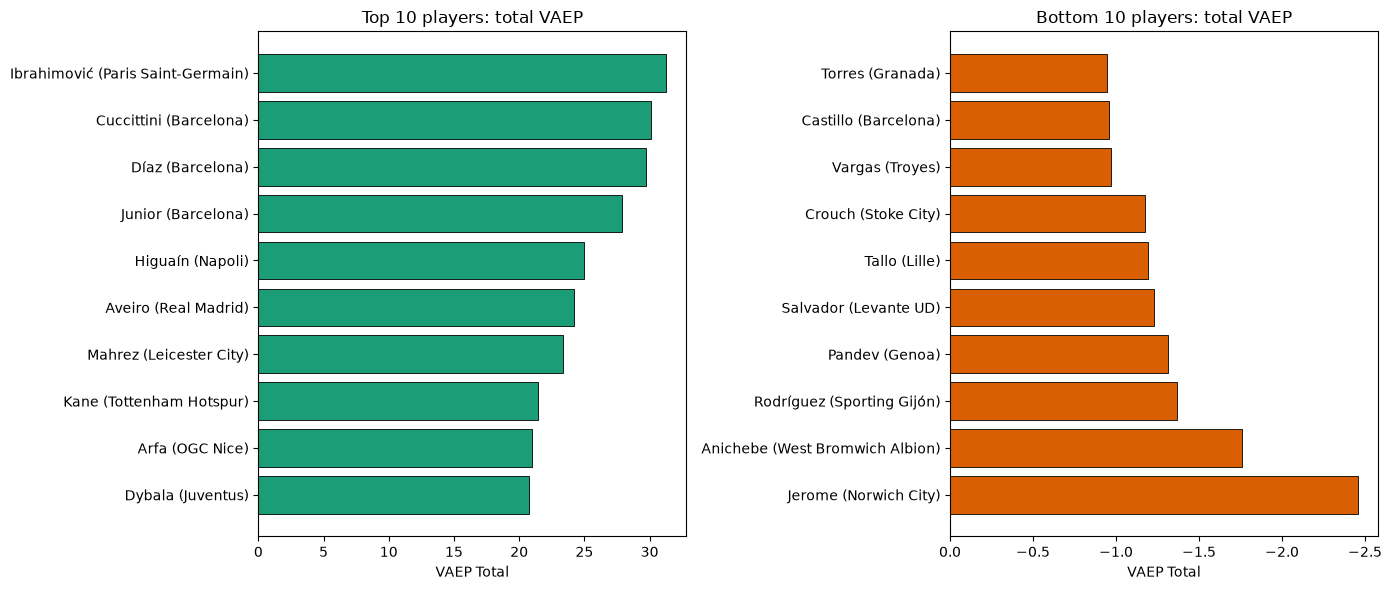

In [12]:
top10_total = total_vaep.head(10).copy()
top10_total['label'] = top10_total['player'].str.split().str[-1] + ' (' + top10_total['team'].fillna('') + ')'

bot10_total = total_vaep.tail(10).copy()
bot10_total['label'] = bot10_total['player'].str.split().str[-1] + ' (' + bot10_total['team'].fillna('') + ')'

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(top10_total['label'][::-1], top10_total['vaep_total'][::-1], color='#1b9e77', edgecolor='black', linewidth=0.6)
axes[0].set_xlim(0, top10_total['vaep_total'].max() * 1.05)
axes[0].set_xlabel('VAEP Total')
axes[0].set_title('Top 10 players: total VAEP')

axes[1].barh(bot10_total['label'][::-1], bot10_total['vaep_total'][::-1], color='#d95f02', edgecolor='black', linewidth=0.6)
axes[1].set_xlim(0, bot10_total['vaep_total'].min() * 1.05)
axes[1].set_xlabel('VAEP Total')
axes[1].set_title('Bottom 10 players: total VAEP')

plt.tight_layout()
fig.savefig(VIZ_PATH / 'vaep_total_players.png', dpi=150, bbox_inches='tight')
plt.show()

## **10. VAEP by team**

Total VAEP of each team's outfield players, with the top ten charted in `viz/vaep_teams.png`.

,team_id,team,vaep_total,min_total,actions
0,220,Real Madrid,143.210999,35285.567,43836
1,217,Barcelona,143.197998,35189.033,48813
2,131,Paris Saint-Germain,131.315994,34373.350,52572
3,229,AS Roma,113.777000,35701.633,39384
4,227,Napoli,109.272003,35493.617,48954
5,36,Manchester City,104.103996,35667.450,42195
6,137,Lyon,101.766998,35623.333,43325
7,224,Juventus,100.415001,35547.333,40635
8,38,Tottenham Hotspur,99.277000,35747.050,37989
9,1,Arsenal,98.007004,35720.833,42354


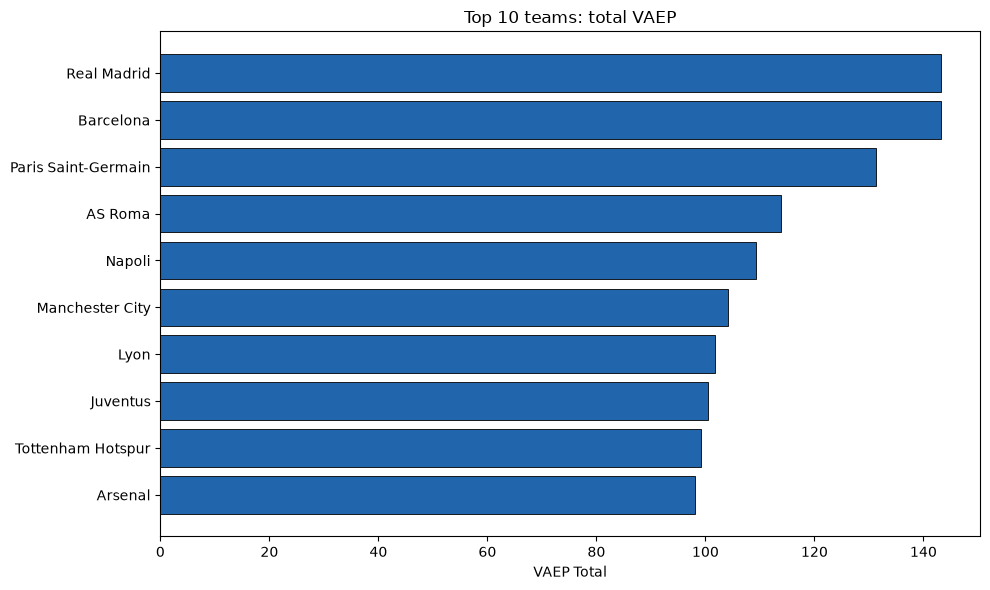

In [13]:
team_vaep = (
    player_match[~player_match['player_id'].isin(goalkeeper_ids)]
    .groupby(['team_id','team'], as_index=False)
    .agg(vaep_total=('vaep_sum','sum'), min_total=('minutes','sum'), actions=('n_actions','sum'))
    .sort_values('vaep_total', ascending=False)
    .reset_index(drop=True)
)

display(team_vaep.head(20).round(3))


top10_teams = team_vaep.head(10)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top10_teams['team'][::-1], top10_teams['vaep_total'][::-1], color='#2166ac', edgecolor='black', linewidth=0.6)
ax.set_xlabel('VAEP Total')
ax.set_title('Top 10 teams: total VAEP')
plt.tight_layout()
fig.savefig(VIZ_PATH / 'vaep_teams.png', dpi=150, bbox_inches='tight')
plt.show()

## **11. VAEP by league**

Mean VAEP per match in each competition, saved to `viz/vaep_leagues.png`.

,competition,vaep_total,matches,min_total,actions,n_players,vaep_per_match
0,Spain - La Liga,1624.430054,380,708221.050,665083,497,4.275
1,England - Premier League,1613.086060,380,716949.167,673977,504,4.245
2,France - Ligue 1,1580.597046,377,705421.867,683611,528,4.193
3,Italy - Serie A,1571.421021,380,713993.250,681194,505,4.135


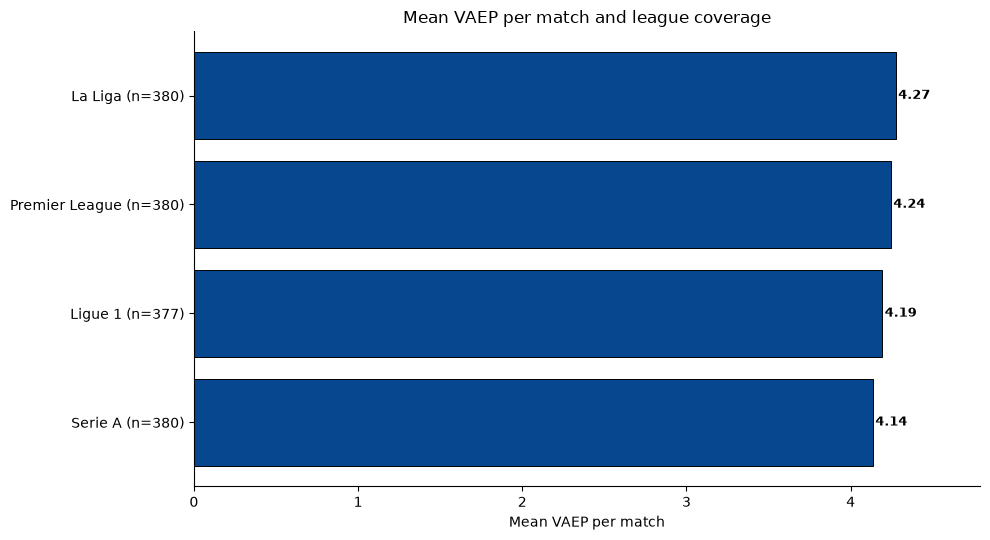

In [14]:
match_competition = matches[['match_id','competition']].drop_duplicates()

league_vaep = (
    player_match[~player_match['player_id'].isin(goalkeeper_ids)]
    .merge(match_competition, on='match_id', how='left')
    .groupby('competition', as_index=False)
    .agg(vaep_total=('vaep_sum','sum'), matches=('match_id','nunique'), min_total=('minutes','sum'), actions=('n_actions','sum'), n_players=('player_id','nunique'))
    .assign(vaep_per_match=lambda d: d['vaep_total'] / d['matches'])
    .sort_values('vaep_per_match', ascending=False)
    .reset_index(drop=True)
)

display(league_vaep.round(3))


league_plot = league_vaep.sort_values('vaep_per_match').copy()
league_plot['competition_label'] = (
    league_plot['competition'].str.replace(r'^[^-]+ - ', '', regex=True)
    + ' (n=' + league_plot['matches'].astype(str) + ')'
)

fig, ax = plt.subplots(figsize=(10, 5.5))
bars = ax.barh(league_plot['competition_label'], league_plot['vaep_per_match'], color='#06478f', edgecolor='black', linewidth=0.7)
for bar, value in zip(bars, league_plot['vaep_per_match']):
    ax.text(value + 0.015, bar.get_y() + bar.get_height() / 2, f'{value:.2f}', va='center', fontweight='bold', fontsize=9)
ax.set_xlim(0, league_plot['vaep_per_match'].max() * 1.12)
ax.set_xlabel('Mean VAEP per match')
ax.set_title('Mean VAEP per match and league coverage')
ax.spines[['top', 'right']].set_visible(False)
ax.grid(False)
plt.tight_layout()
fig.savefig(VIZ_PATH / 'vaep_leagues.png', dpi=150, bbox_inches='tight')
plt.show()

## **12. Minutes per match for the whole squad**

**Part 2: Synergy VAEP.** For each team and match played, records the minutes of **every** player in the squad for that season and competition. Players who did not take the pitch receive `minutes = 0`.

Output columns: `team_id`, `team`, `match_id`, `player_id`, `player`, `minutes`, `started`, `subbed_out`, `sub_replacement_id`, `came_as_sub`.

In [15]:
def build_team_rosters(ev):
    direct = ev.loc[
        ev['player_id'].notna() & ev['team_id'].notna(),
        ['team_id', 'team', 'player_id', 'player']
    ].dropna(subset=['player_id']).copy()
    direct['player_id'] = direct['player_id'].astype(int)
    direct['team_id']   = direct['team_id'].astype(int)

    subs = ev.loc[
        ev['substitution_replacement_id'].notna() & ev['team_id'].notna(),
        ['team_id', 'team', 'substitution_replacement_id', 'substitution_replacement']
    ].rename(columns={
        'substitution_replacement_id': 'player_id',
        'substitution_replacement':    'player'
    }).dropna(subset=['player_id']).copy()
    subs['player_id'] = subs['player_id'].astype(int)
    subs['team_id']   = subs['team_id'].astype(int)

    combined = pd.concat([direct, subs], ignore_index=True)
    return combined.drop_duplicates(['team_id', 'player_id']).reset_index(drop=True)


def build_full_player_match_minutes(ev, pm, rosters):
    subs = ev.loc[
        ev['type'].eq('Substitution') &
        ev['player_id'].notna() &
        ev['substitution_replacement_id'].notna(),
        ['match_id', 'team_id', 'player_id', 'substitution_replacement_id']
    ].copy()
    subs['player_id']                   = subs['player_id'].astype(int)
    subs['substitution_replacement_id'] = subs['substitution_replacement_id'].astype(int)
    subs['team_id']                     = subs['team_id'].astype(int)

    sub_out_map = {}
    sub_in_set  = set()
    for row in subs.itertuples(index=False):
        sub_out_map[(row.match_id, row.team_id, row.player_id)] = int(row.substitution_replacement_id)
        sub_in_set.add((row.match_id, row.team_id, int(row.substitution_replacement_id)))

    starting_xi = {}
    for row in ev.loc[ev['type'].eq('Starting XI'), ['match_id', 'team_id', 'tactics']].itertuples(index=False):
        tactics = parse_tactics(row.tactics)
        pids = {int(item['player']['id']) for item in tactics.get('lineup', [])
                if item.get('player', {}).get('id') is not None}
        starting_xi[(row.match_id, int(row.team_id))] = pids

    pm_idx = (
        pm.assign(team_id=lambda d: d['team_id'].astype(int), player_id=lambda d: d['player_id'].astype(int))
        .set_index(['match_id', 'team_id', 'player_id'])['minutes']
        .to_dict()
    )

    team_matches = (
        pm[['match_id', 'team_id', 'team']].drop_duplicates()
        .assign(team_id=lambda d: d['team_id'].astype(int))
    )

    roster_by_team = {
        int(tid): grp for tid, grp in rosters.groupby('team_id')
    }

    rows = []
    for rec in team_matches.itertuples(index=False):
        match_id, team_id, team = rec.match_id, int(rec.team_id), rec.team
        roster_grp = roster_by_team.get(team_id)
        if roster_grp is None:
            continue
        starters = starting_xi.get((match_id, team_id), set())

        for pr in roster_grp.itertuples(index=False):
            pid     = int(pr.player_id)
            minutes = float(pm_idx.get((match_id, team_id, pid), 0.0))
            started = pid in starters
            repl_id = sub_out_map.get((match_id, team_id, pid))
            rows.append({
                'match_id':          match_id,
                'team_id':           team_id,
                'team':              team,
                'player_id':         pid,
                'player':            pr.player,
                'minutes':           minutes,
                'started':           started,
                'subbed_out':        repl_id is not None,
                'sub_replacement_id': repl_id,
                'came_as_sub':       (match_id, team_id, pid) in sub_in_set,
            })

    return pd.DataFrame(rows)


team_rosters          = build_team_rosters(events)
full_player_match_min = build_full_player_match_minutes(events, player_min, team_rosters)

print(f'Total records (player × match): {len(full_player_match_min):,}')
print(f'  With 0 minutes (did not play): {full_player_match_min["minutes"].eq(0).sum():,}')
print(f'  Starters:                      {full_player_match_min["started"].sum():,}')
print(f'  Substituted off:               {full_player_match_min["subbed_out"].sum():,}')
print(f'  Came on as substitutes:        {full_player_match_min["came_as_sub"].sum():,}')


sample_team_id = int(full_player_match_min['team_id'].value_counts().idxmax())
sample_matches = (
    full_player_match_min[full_player_match_min['team_id'].eq(sample_team_id)]
    ['match_id'].unique()[:3]
)

(
    full_player_match_min[
        full_player_match_min['team_id'].eq(sample_team_id) &
        full_player_match_min['match_id'].isin(sample_matches)
    ]
    .sort_values(['match_id', 'minutes'], ascending=[True, False])
    [['team', 'match_id', 'player', 'minutes', 'started', 'subbed_out', 'came_as_sub']]
    .head(30)
)

Total records (player × match): 86,503
  With 0 minutes (did not play): 44,407
  Starters:                      33,374
  Substituted off:               8,722
  Came on as substitutes:        8,722


,team,match_id,player,minutes,started,subbed_out,came_as_sub
48873,Sampdoria,3878545,Eder Citadin Martins,92.916667,True,False,False
48874,Sampdoria,3878545,Fernando Lucas Martins,92.916667,True,False,False
48875,Sampdoria,3878545,Vasco Regini,92.916667,True,False,False
48876,Sampdoria,3878545,Andrea Coda,92.916667,True,False,False
48877,Sampdoria,3878545,Dávid Ivan,92.916667,True,False,False
48878,Sampdoria,3878545,Mattia Cassani,92.916667,True,False,False
48879,Sampdoria,3878545,Édgar Osvaldo Barreto Cáceres,92.916667,True,False,False
48881,Sampdoria,3878545,Emiliano Viviano,92.916667,True,False,False
48882,Sampdoria,3878545,Matías Agustín Silvestre,92.916667,True,False,False
48872,Sampdoria,3878545,Roberto Soriano,82.850000,True,True,False


## **13. Spatial occurrence matrix (14 × 10)**

For each player with at least 600 total minutes, events are counted on a **14 × 10** grid (120 m × 80 m) and normalized by the player's total events. The resulting vector (**140 dimensions**) is the spatial profile of each player.

PCA in its snapshot/SVD formulation, with the same methodology as the eigen-heatmaps, reduces it to the `k` components that explain ≥ 90 % of the variance, with no manual cap. Similarity between players uses **cosine distance** in the reduced space.

In [16]:
OMAT_X_BINS          = 14
OMAT_Y_BINS          = 10
OCC_VARIANCE_TARGET  = 0.90
MIN_EIGENMAP_MINUTES = 600.0

NON_SPATIAL_TYPES = {
    'Starting XI', 'Half Start', 'Half End', 'Tactical Shift',
    'Substitution', 'Player Off', 'Player On', 'Injury Stoppage',
    'Bad Behaviour', 'Referee Ball-Drop',
}

def build_occurrence_matrix(ev, player_qual, gk_ids, x_bins=14, y_bins=10):
    eligible_players = set(
        player_qual.loc[player_qual['min_total'].ge(MIN_EIGENMAP_MINUTES), 'player_id']
        .dropna()
        .astype(int)
    )

    spatial = ev.loc[
        ev['team_id'].notna()    & ev['player_id'].notna() &
        ev['location_x'].notna() & ev['location_y'].notna() &
        ~ev['type'].isin(NON_SPATIAL_TYPES),
        ['player_id', 'team_id', 'team', 'player', 'location_x', 'location_y']
    ].copy()
    spatial['player_id']  = spatial['player_id'].astype(int)
    spatial['team_id']    = spatial['team_id'].astype(int)
    spatial = spatial[~spatial['player_id'].isin(gk_ids)]
    spatial = spatial[spatial['player_id'].isin(eligible_players)].copy()
    spatial['location_x'] = pd.to_numeric(spatial['location_x'], errors='coerce')
    spatial['location_y'] = pd.to_numeric(spatial['location_y'], errors='coerce')
    spatial = spatial[
        spatial['location_x'].between(0, 120, inclusive='both') &
        spatial['location_y'].between(0, 80,  inclusive='both')
    ].copy()

    x_edges = np.linspace(0, 120, x_bins + 1)
    y_edges = np.linspace(0, 80,  y_bins + 1)
    spatial['x_bin'] = pd.cut(spatial['location_x'], bins=x_edges, labels=False,
                               include_lowest=True).astype(int)
    spatial['y_bin'] = pd.cut(spatial['location_y'], bins=y_edges, labels=False,
                               include_lowest=True).astype(int)
    spatial['cell']  = spatial['x_bin'] * y_bins + spatial['y_bin']

    player_info = (
        spatial.groupby('player_id', as_index=False)
        .agg(player=('player', 'first'), team=('team', 'first'),
             team_id=('team_id', 'first'), n_events=('cell', 'count'))
    )

    n_players = len(player_info)
    n_cells   = x_bins * y_bins
    occ_raw   = np.zeros((n_players, n_cells), dtype=np.float32)

    pid_to_row = {int(pid): i for i, pid in enumerate(player_info['player_id'])}

    counts = spatial.groupby(['player_id', 'cell']).size().reset_index(name='cnt')
    for row in counts.itertuples(index=False):
        r = pid_to_row.get(int(row.player_id))
        if r is not None and 0 <= int(row.cell) < n_cells:
            occ_raw[r, int(row.cell)] = row.cnt

    row_sums = occ_raw.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1.0
    occ_matrix = (occ_raw / row_sums).astype(np.float64)

    return player_info, occ_matrix


occ_players, occ_matrix = build_occurrence_matrix(events, player_quality, goalkeeper_ids, OMAT_X_BINS, OMAT_Y_BINS)
print(f'Players in the spatial space: {len(occ_players):,}')
print(f'Vector dimension:             {occ_matrix.shape[1]}  ({OMAT_X_BINS}×{OMAT_Y_BINS})')


from scipy.spatial.distance import cdist

def compute_pca_snapshot(X_in, variance_target=0.90, eps=1e-12):
    X_mean     = X_in.mean(axis=0, keepdims=True)
    X_centered = X_in - X_mean
    n = X_centered.shape[0]

    gram     = (X_centered @ X_centered.T) / max(n - 1, 1)
    eigvals, eigvecs = np.linalg.eigh(gram)
    order    = np.argsort(eigvals)[::-1]
    eigvals  = eigvals[order];  eigvecs = eigvecs[:, order]

    valid   = eigvals > eps
    eigvals = eigvals[valid];   eigvecs = eigvecs[:, valid]

    singular = np.sqrt(eigvals * max(n - 1, 1))
    cumul    = np.cumsum(eigvals / eigvals.sum())
    k_var    = int(np.searchsorted(cumul, variance_target) + 1)
    k        = int(min(max(2, k_var), eigvecs.shape[1]))

    spatial_modes = (X_centered.T @ eigvecs[:, :k]) / singular[:k]
    scores        = eigvecs[:, :k] * singular[:k]
    embedding     = scores / np.sqrt(np.maximum(eigvals[:k], eps))

    return X_mean, eigvals, embedding, spatial_modes, cumul, k


occ_X_mean, occ_eigvals, occ_embedding, occ_spatial_modes, occ_cumul, occ_k = compute_pca_snapshot(
    occ_matrix, variance_target=OCC_VARIANCE_TARGET
)

print(f'Selected components: {occ_k}')
print(f'Explained variance:       {occ_cumul[occ_k - 1]:.4f}')
print(f'Embedding shape:          {occ_embedding.shape}')

occ_cosine_dist = cdist(occ_embedding, occ_embedding, metric='cosine')
occ_pid_to_idx  = {int(pid): i for i, pid in enumerate(occ_players['player_id'])}


def most_similar_player(focal_pid, candidate_pids):
    fi = occ_pid_to_idx.get(int(focal_pid))
    if fi is None:
        return None
    best_dist, best_pid = np.inf, None
    for cid in candidate_pids:
        ci = occ_pid_to_idx.get(int(cid))
        if ci is None or ci == fi:
            continue
        d = float(occ_cosine_dist[fi, ci])
        if d < best_dist:
            best_dist, best_pid = d, int(cid)
    return best_pid

Players in the spatial space: 1,435
Vector dimension:             140  (14×10)
Selected components: 11
Explained variance:       0.9024
Embedding shape:          (1435, 11)


## **14. Proxy player per match**

For each `(player, match)` pair, the proxy follows one of three rules:

| case | condition | method | proxy |
|---|---|---|---|
| 1 | started and played the whole match | `full_match` | not applicable |
| 2 | started but was substituted | `direct_sub` | player who came on in their place |
| 3 | did not start (0 minutes or came on as a substitute) | `spatial_similarity` | player with the most similar occurrence vector |

In [17]:
def build_proxy_per_match(full_pm, player_lk):
    subs_ev = events.loc[
        events['type'].eq('Substitution') &
        events['player_id'].notna() &
        events['substitution_replacement_id'].notna(),
        ['match_id', 'team_id', 'player_id', 'substitution_replacement_id']
    ].copy()
    subs_ev['player_id']                   = subs_ev['player_id'].astype(int)
    subs_ev['substitution_replacement_id'] = subs_ev['substitution_replacement_id'].astype(int)
    subs_ev['team_id']                     = subs_ev['team_id'].astype(int)
    sub_lookup = {
        (r.match_id, r.team_id, r.player_id): r.substitution_replacement_id
        for r in subs_ev.itertuples(index=False)
    }

    name_lk = player_lk.set_index('player_id')['player'].to_dict()

    team_roster = {
        int(k): v for k, v in full_pm.groupby('team_id')['player_id'].apply(set).to_dict().items()
    }

    rows = []
    for rec in full_pm.itertuples(index=False):
        pid     = int(rec.player_id)
        mid     = rec.match_id
        tid     = int(rec.team_id)

        if rec.started and not rec.subbed_out:
            proxy_id, proxy_method = None, 'full_match'

        elif rec.started and rec.subbed_out:
            proxy_id     = sub_lookup.get((mid, tid, pid))
            proxy_method = 'direct_sub' if proxy_id is not None else 'spatial_similarity'
            if proxy_id is None:
                candidates = team_roster.get(tid, set()) - {pid}
                proxy_id   = most_similar_player(pid, candidates)

        else:
            candidates = team_roster.get(tid, set()) - {pid}
            proxy_id   = most_similar_player(pid, candidates)
            proxy_method = 'spatial_similarity' if proxy_id is not None else 'no_proxy'

        rows.append({
            'match_id':     mid,
            'team_id':      tid,
            'team':         rec.team,
            'player_id':    pid,
            'player':       rec.player,
            'minutes':      float(rec.minutes),
            'started':      rec.started,
            'subbed_out':   rec.subbed_out,
            'came_as_sub':  rec.came_as_sub,
            'proxy_id':     proxy_id,
            'proxy_player': name_lk.get(int(proxy_id)) if proxy_id is not None else None,
            'proxy_method': proxy_method,
        })

    return pd.DataFrame(rows)


player_match_proxy = build_proxy_per_match(full_player_match_min, player_lookup)

print(f'Total records (player × match): {len(player_match_proxy):,}')
print('\nDistribution by proxy method:')
print(player_match_proxy['proxy_method'].value_counts())


player_match_proxy.to_parquet(PROCESSED_PATH / 'player_match_proxy.parquet', index=False)
print(f'Saved to: {PROCESSED_PATH / "player_match_proxy.parquet"}')

(
    player_match_proxy[player_match_proxy['team_id'].eq(sample_team_id)]
    .sort_values(['match_id', 'proxy_method', 'minutes'], ascending=[True, True, False])
    [['team', 'match_id', 'player', 'minutes', 'started', 'subbed_out',
      'came_as_sub', 'proxy_method', 'proxy_player']]
    .head(30)
)

Total records (player × match): 86,503

Distribution by proxy method:
proxy_method
spatial_similarity    28533
full_match            24687
no_proxy              24596
direct_sub             8687
Name: count, dtype: int64
Saved to: /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/data/processed/player_match_proxy.parquet


,team,match_id,player,minutes,started,subbed_out,came_as_sub,proxy_method,proxy_player
48872,Sampdoria,3878545,Roberto Soriano,82.850000,True,True,False,direct_sub,Paweł Wszołek
48880,Sampdoria,3878545,Luis Fernando Muriel Fruto,73.033333,True,True,False,direct_sub,Antonio Cassano
48873,Sampdoria,3878545,Eder Citadin Martins,92.916667,True,False,False,full_match,NaN
48874,Sampdoria,3878545,Fernando Lucas Martins,92.916667,True,False,False,full_match,NaN
48875,Sampdoria,3878545,Vasco Regini,92.916667,True,False,False,full_match,NaN
48876,Sampdoria,3878545,Andrea Coda,92.916667,True,False,False,full_match,NaN
48877,Sampdoria,3878545,Dávid Ivan,92.916667,True,False,False,full_match,NaN
48878,Sampdoria,3878545,Mattia Cassani,92.916667,True,False,False,full_match,NaN
48879,Sampdoria,3878545,Édgar Osvaldo Barreto Cáceres,92.916667,True,False,False,full_match,NaN
48881,Sampdoria,3878545,Emiliano Viviano,92.916667,True,False,False,full_match,NaN


## **15. Synergy settings**

A relation enters the calculation only with at least `MIN_TOGETHER_MINUTES` minutes together and `MIN_REPLACEMENT_MINUTES` minutes with the proxy.

In [18]:
MIN_TOGETHER_MINUTES = 300.0
MIN_REPLACEMENT_MINUTES = 180.0

## **16. Positions and spatial profiles**

Each player eligible by minutes is represented by a normalized 2D histogram of event locations. PCA compresses it to the `k` components that explain ≥ 90 % of the variance, with no manual cap. Similarity is the cosine between normalized embeddings.

In [19]:
NON_ROLE_EVENT_TYPES = {
    'Starting XI','Half Start','Half End','Tactical Shift',
    'Substitution','Player Off','Player On','Injury Stoppage',
    'Bad Behaviour','Referee Ball-Drop',
}

def build_position_lookup(ev):
    rows = []
    for row in ev.loc[ev['type'].eq('Starting XI'), ['match_id','team_id','team','tactics']].itertuples(index=False):
        tactics = parse_tactics(row.tactics)
        for item in tactics.get('lineup', []):
            player   = item.get('player', {})
            position = item.get('position', {})
            pid = player.get('id')
            if pid is None: continue
            rows.append({'team_id':int(row.team_id),'team':row.team,'player_id':int(pid),'lineup_position':position.get('name')})
    if not rows:
        return pd.DataFrame(columns=['team_id','player_id','lineup_position'])
    positions = pd.DataFrame(rows)
    return (
        positions.groupby(['team_id','team','player_id'], as_index=False)
        .agg(lineup_position=('lineup_position', lambda x: x.dropna().astype(str).mode().iloc[0] if not x.dropna().empty else None))
    )

def build_role_profiles(ev, player_lk, pos_lk, player_qual, gk_ids):
    eligible_players = set(
        player_qual.loc[player_qual['min_total'].ge(MIN_EIGENMAP_MINUTES), 'player_id']
        .dropna()
        .astype(int)
    )

    role_ev = ev.loc[
        ev['team_id'].notna() & ev['player_id'].notna() &
        ev['location_x'].notna() & ev['location_y'].notna() &
        ~ev['type'].isin(NON_ROLE_EVENT_TYPES),
        ['team_id','team','player_id','player','type','location_x','location_y']
    ].copy()
    role_ev['team_id']   = role_ev['team_id'].astype(int)
    role_ev['player_id'] = role_ev['player_id'].astype(int)
    role_ev = role_ev[~role_ev['player_id'].isin(gk_ids)]
    role_ev = role_ev[role_ev['player_id'].isin(eligible_players)].copy()
    role_ev['location_x'] = pd.to_numeric(role_ev['location_x'], errors='coerce')
    role_ev['location_y'] = pd.to_numeric(role_ev['location_y'], errors='coerce')
    role_ev = role_ev[role_ev['location_x'].between(0,120) & role_ev['location_y'].between(0,80)].copy()

    x_edges = np.linspace(0, 120, OMAT_X_BINS + 1)
    y_edges = np.linspace(0, 80,  OMAT_Y_BINS + 1)

    rows, vectors = [], []
    for (team_id, player_id), grp in role_ev.groupby(['team_id','player_id'], sort=True):
        hist, _, _ = np.histogram2d(grp['location_y'].to_numpy(float), grp['location_x'].to_numpy(float), bins=[y_edges, x_edges])
        total = hist.sum()
        if total <= 0: continue
        density = (hist / total).astype(float)
        vectors.append(density.reshape(-1))
        rows.append({'team_id':int(team_id),'player_id':int(player_id),'role_events':int(len(grp)),
                     'mean_x':float(grp['location_x'].mean()),'mean_y':float(grp['location_y'].mean()),
                     'defensive_third_share':float((grp['location_x']<40).mean()),
                     'attacking_third_share':float((grp['location_x']>=80).mean())})

    profiles  = pd.DataFrame(rows)
    x_matrix  = np.vstack(vectors)
    x_mean    = x_matrix.mean(axis=0, keepdims=True)
    x_ctr     = x_matrix - x_mean
    _, sv, vt = np.linalg.svd(x_ctr, full_matrices=False)
    eigvals   = (sv**2) / max(len(x_matrix)-1, 1)
    cumulative= np.cumsum(eigvals / eigvals.sum())
    k = int(min(max(2, int(np.searchsorted(cumulative, OCC_VARIANCE_TARGET)+1)), vt.shape[0]))
    scores_raw = x_ctr @ vt[:k].T
    score_mean = scores_raw.mean(axis=0, keepdims=True)
    score_std  = scores_raw.std(axis=0, keepdims=True) + 1e-12
    scores     = (scores_raw - score_mean) / score_std
    embeddings = scores / np.maximum(np.linalg.norm(scores, axis=1, keepdims=True), 1e-12)
    pca_artifacts = dict(x_mean=x_mean.squeeze(), directions=vt[:k],
                         score_mean=score_mean.squeeze(), score_std=score_std.squeeze(), k=k)
    np.savez(PROCESSED_PATH / 'role_pca_artifacts.npz', **pca_artifacts)

    profiles = pd.concat([
        profiles.reset_index(drop=True),
        pd.DataFrame({f'role_pc_{i+1}' : scores[:,i]     for i in range(k)}),
        pd.DataFrame({f'role_emb_{i+1}': embeddings[:,i] for i in range(k)}),
        pd.DataFrame({f'role_bin_{i:02d}': x_matrix[:,i] for i in range(x_matrix.shape[1])}),
    ], axis=1)
    profiles = profiles.merge(player_lk, on=['team_id','player_id'], how='left')
    profiles = profiles.merge(pos_lk[['team_id','player_id','lineup_position']], on=['team_id','player_id'], how='left')
    profiles['role_components']         = k
    profiles['role_explained_variance'] = float(cumulative[k-1])
    profiles.to_parquet(PROCESSED_PATH / 'player_role_profiles.parquet', index=False)

    emb_cols = [f'role_emb_{i+1}' for i in range(k)]
    sim_rows = []
    for team_id, tp in profiles.groupby('team_id', sort=False):
        ids = tp['player_id'].astype(int).to_numpy()
        emb = tp[emb_cols].to_numpy(float)
        if len(ids) < 2: continue
        sim = emb @ emb.T
        for i, t in enumerate(ids):
            for j, c in enumerate(ids):
                if i == j: continue
                sim_rows.append({'team_id':int(team_id),'target_player_id':int(t),'candidate_player_id':int(c),'role_similarity':float(sim[i,j])})
    similarities = pd.DataFrame(sim_rows)
    similarities.to_parquet(PROCESSED_PATH / 'player_role_similarity.parquet', index=False)
    return profiles, similarities, pca_artifacts

position_lookup            = build_position_lookup(events)
role_profiles, similarities, pca_artifacts = build_role_profiles(events, player_lookup, position_lookup, player_quality, goalkeeper_ids)
print(f'Profiles: {len(role_profiles):,}  |  Similarity pairs: {len(similarities):,}')


MIN_MATCH_PROJ_EVENTS = 30

def compute_match_projections(ev, pca_art, gk_ids):
    x_mean = pca_art['x_mean']
    directions = pca_art['directions']
    s_mean = pca_art['score_mean']
    s_std = pca_art['score_std']
    k = int(pca_art['k'])

    role_ev = ev.loc[
        ev['match_id'].notna() & ev['team_id'].notna() & ev['player_id'].notna() &
        ev['location_x'].notna() & ev['location_y'].notna() &
        ~ev['type'].isin(NON_ROLE_EVENT_TYPES),
        ['match_id', 'player_id', 'location_x', 'location_y']
    ].copy()
    role_ev['player_id'] = role_ev['player_id'].astype(int)
    role_ev = role_ev[~role_ev['player_id'].isin(gk_ids)]
    role_ev['location_x'] = pd.to_numeric(role_ev['location_x'], errors='coerce')
    role_ev['location_y'] = pd.to_numeric(role_ev['location_y'], errors='coerce')
    role_ev = role_ev[role_ev['location_x'].between(0, 120) & role_ev['location_y'].between(0, 80)]

    x_edges = np.linspace(0, 120, OMAT_X_BINS + 1)
    y_edges = np.linspace(0, 80,  OMAT_Y_BINS + 1)
    emb_cols = [f'match_emb_{i+1}' for i in range(k)]

    rows = []
    for (match_id, player_id), grp in role_ev.groupby(['match_id', 'player_id'], sort=False):
        if len(grp) < MIN_MATCH_PROJ_EVENTS:
            continue
        hist, _, _ = np.histogram2d(
            grp['location_y'].to_numpy(float), grp['location_x'].to_numpy(float),
            bins=[y_edges, x_edges]
        )
        total = hist.sum()
        if total <= 0:
            continue
        density = (hist / total).reshape(-1)
        raw = (density - x_mean) @ directions.T
        std_sc = (raw - s_mean) / s_std
        norm_val = np.maximum(np.linalg.norm(std_sc), 1e-12)
        emb = std_sc / norm_val
        row = {'match_id': match_id, 'player_id': int(player_id)}
        for i, c in enumerate(emb_cols):
            row[c] = float(emb[i])
        rows.append(row)

    return pd.DataFrame(rows)


match_projections = compute_match_projections(events, pca_artifacts, goalkeeper_ids)
match_projections.to_parquet(PROCESSED_PATH / 'player_match_projections.parquet', index=False)
print(f'Match projections: {len(match_projections):,}  |  components: {int(pca_artifacts["k"])}')

Profiles: 1,560  |  Similarity pairs: 29,982


Match projections: 35,881  |  components: 21


## **17. Proxy selection and sample accumulation**

For each segment with an absent player, the proxy is chosen by:

1. The current occupant of the same substitution slot (`same_substitution_slot`).
2. The slot starter with the highest positional compatibility plus **similarity between the absent player's global embedding and each starter's match embedding** (`starter_similarity_slot`). The match embedding projects that match's events onto the global PCA space (section 16), using at least `MIN_MATCH_PROJ_EVENTS` positional events. It falls back to the static global similarity when the match projection is not available.

In [20]:
def _norm_pos(p):
    return '' if (p is None or (isinstance(p, float) and np.isnan(p))) else str(p).strip().lower()

def _pos_side(p):
    t = _norm_pos(p)
    if t.startswith('left')  or ' left '  in f' {t} ': return 'left'
    if t.startswith('right') or ' right ' in f' {t} ': return 'right'
    return None

def _pos_role(p):
    t = _norm_pos(p)
    if not t: return 'unknown'
    if 'goalkeeper'         in t: return 'goalkeeper'
    if 'center back'        in t or 'centre back' in t: return 'center_back'
    if 'back'               in t: return 'fullback'
    if 'defensive midfield' in t: return 'defensive_midfield'
    if 'attacking midfield' in t: return 'attacking_midfield'
    if 'midfield'           in t: return 'central_midfield'
    if 'wing'               in t: return 'winger'
    if 'forward' in t or 'striker' in t: return 'forward'
    return 'unknown'

def _pos_compat(target, candidate):
    tr, cr = _pos_role(target), _pos_role(candidate)
    if tr in {'goalkeeper','unknown'} or cr in {'goalkeeper','unknown'}: return 0
    ts, cs = _pos_side(target), _pos_side(candidate)
    tn, cn = _norm_pos(target), _norm_pos(candidate)
    if tn == cn: return 6
    table = {
        ('winger','winger'):(5 if ts and ts==cs else 4),('winger','forward'):3,('winger','attacking_midfield'):2,
        ('forward','forward'):5,('forward','winger'):4,('forward','attacking_midfield'):3,
        ('attacking_midfield','attacking_midfield'):5,('attacking_midfield','central_midfield'):4,
        ('attacking_midfield','winger'):3,('attacking_midfield','forward'):3,('attacking_midfield','defensive_midfield'):2,
        ('central_midfield','central_midfield'):5,('central_midfield','defensive_midfield'):4,('central_midfield','attacking_midfield'):4,
        ('defensive_midfield','defensive_midfield'):5,('defensive_midfield','central_midfield'):4,('defensive_midfield','center_back'):2,
        ('fullback','fullback'):(5 if ts and ts==cs else 3),('fullback','center_back'):1,
        ('center_back','center_back'):5,('center_back','fullback'):2,('center_back','defensive_midfield'):2,
    }
    return table.get((tr,cr), 0)

def _sim_or_zero(sim_lk, team_id, target, candidate):
    v = sim_lk.get((int(team_id), int(target), int(candidate)))
    return float(v) if v is not None and np.isfinite(v) else 0.0

def choose_proxy(seg, team_id, focal_id, absent_id, active, sim_lk, pos_lk_dict, gk_ids,
                 match_proj_lk=None, absent_emb_lk=None):
    cur_by_slot = {int(s): int(p) for s,p in seg.slot_players}
    p2s         = {int(p): int(s) for p,s in seg.match_player_slots}
    starters    = {int(s): int(p) for s,p,_ in seg.starter_slots}
    starter_pos = {int(s): pos    for s,_,pos in seg.starter_slots}

    if int(absent_id) in p2s:
        sid = p2s[int(absent_id)]
        prx = cur_by_slot.get(sid)
        if prx and prx != int(focal_id) and prx in active and prx not in gk_ids:
            return int(prx), int(absent_id), 'same_substitution_slot', _sim_or_zero(sim_lk, team_id, absent_id, prx)
        return None, None, None, np.nan

    target_pos = pos_lk_dict.get((int(team_id), int(absent_id)))
    best = None

    absent_emb = None
    if match_proj_lk is not None and absent_emb_lk is not None:
        absent_emb = absent_emb_lk.get((int(team_id), int(absent_id)))

    for sid, stid in starters.items():
        prx = cur_by_slot.get(int(sid))
        if not prx or stid in gk_ids or prx in gk_ids: continue
        if stid == int(focal_id) or prx == int(focal_id) or prx not in active: continue
        compat = _pos_compat(target_pos, starter_pos.get(int(sid)))
        if compat <= 0: continue
        if absent_emb is not None:
            prx_emb = match_proj_lk.get((int(seg.match_id), int(prx)))
            if prx_emb is None:
                continue
            sim = float(np.dot(absent_emb, prx_emb))
        else:
            sim = sim_lk.get((int(team_id), int(absent_id), stid))
            if sim is None or not np.isfinite(sim): continue
        cand = (int(compat), float(sim), int(sid), stid, int(prx))
        if best is None or cand[:2] > best[:2]: best = cand

    if best is None: return None, None, None, np.nan
    _, sim, _, anchor, prx = best
    return int(prx), int(anchor), 'starter_similarity_slot', float(sim)


def build_player_windows(pm, gk_ids):
    base = (
        pm[~pm['player_id'].isin(gk_ids)]
        .assign(match_date=lambda d: pd.to_datetime(d['match_date']))
    )
    player_totals = (
        base.groupby(['season','team_id','player_id'], as_index=False)
        .agg(min_total=('minutes','sum'))
    )
    season_windows = (
        base.groupby(['season','team_id'], as_index=False)
        .agg(first_date=('match_date','min'), last_date=('match_date','max'))
    )
    w = player_totals.merge(season_windows, on=['season','team_id'], how='left')
    w['team_id']   = w['team_id'].astype(int)
    w['player_id'] = w['player_id'].astype(int)
    return w

def aggregate_role_adjusted_samples(segs, vaep_act, windows, role_prof, sims, pos_lk, gk_ids, match_proj=None):
    FIELDS = ['minutes_together','focal_vaep_together','partner_vaep_together','duo_vaep_together',
              'duo_pos_vaep_together','focal_actions_together','partner_actions_together','duo_actions_together',
              'minutes_proxy','focal_vaep_proxy','proxy_vaep','proxy_pos_vaep','proxy_duo_vaep',
              'proxy_duo_pos_vaep','focal_actions_proxy','proxy_actions','proxy_duo_actions',
              'proxy_similarity_minutes','proxy_segments','same_slot_proxy_minutes','starter_similarity_proxy_minutes']
    samp_dict = defaultdict(lambda: {f: 0.0 for f in FIELDS})
    prx_min   = defaultdict(float)
    prx_sim   = defaultdict(float)
    sim_lk = {(int(r.team_id), int(r.target_player_id), int(r.candidate_player_id)): float(r.role_similarity)
               for r in sims.itertuples(index=False)}
    pos_lk_dict = {(int(r.team_id), int(r.player_id)): r.lineup_position
                    for r in pos_lk[['team_id','player_id','lineup_position']].dropna(subset=['team_id','player_id']).itertuples(index=False)}
    profiled = {(int(r.team_id), int(r.player_id)) for r in role_prof[['team_id','player_id']].itertuples(index=False)}
    emb_cols = [c for c in role_prof.columns if c.startswith('role_emb_')]
    absent_emb_lk = {(int(r.team_id), int(r.player_id)):
                     np.array([getattr(r, c) for c in emb_cols], dtype=float)
                     for r in role_prof[['team_id','player_id'] + emb_cols].itertuples()}
    if match_proj is not None and not match_proj.empty:
        proj_cols = [c for c in match_proj.columns if c.startswith('match_emb_')]
        match_proj_lk = {(int(r.match_id), int(r.player_id)):
                         np.array([getattr(r, c) for c in proj_cols], dtype=float)
                         for r in match_proj[['match_id','player_id'] + proj_cols].itertuples()}
    else:
        match_proj_lk = None

    action_base = (
        vaep_act.loc[vaep_act['player_id'].notna(), ['match_id','team_id','event_minute','player_id','vaep']].copy()
        .assign(team_id=lambda d: d['team_id'].astype(int), player_id=lambda d: d['player_id'].astype(int))
    )
    action_base = action_base[~action_base['player_id'].isin(gk_ids)]
    action_groups = {k: g.sort_values('event_minute')[['event_minute','player_id','vaep']]
                     for k, g in action_base.groupby(['match_id','team_id'], sort=False)}
    window_groups = {k: g[['player_id','first_date','last_date']].copy()
                     for k, g in windows.groupby(['season','team_id'], sort=False)}

    for seg in segs.itertuples(index=False):
        team_id = int(seg.team_id)
        active_all      = {int(p) for p in seg.active if int(p) not in gk_ids}
        active_profiled = {p for p in active_all if (team_id, p) in profiled}
        if len(active_profiled) < 1: continue

        wg = window_groups.get((seg.season, team_id))
        if wg is None or wg.empty: continue

        mdate     = pd.to_datetime(seg.match_date)
        available = set(wg.loc[wg['first_date'].le(mdate) & wg['last_date'].ge(mdate), 'player_id'].astype(int)) | active_profiled
        available = {int(p) for p in available if int(p) not in gk_ids and (team_id, int(p)) in profiled}
        absent    = available - active_profiled

        ag = action_groups.get((seg.match_id, team_id))
        if ag is None:
            seg_actions = pd.DataFrame(columns=['player_id','vaep'])
        else:
            mask = ag['event_minute'].ge(seg.start_minute) & ag['event_minute'].lt(seg.end_minute)
            seg_actions = ag.loc[mask][lambda d: d['player_id'].isin(active_all)]

        vaep_map    = seg_actions.groupby('player_id')['vaep'].sum().to_dict()
        pos_map     = seg_actions.assign(pv=seg_actions['vaep'].clip(lower=0)).groupby('player_id')['pv'].sum().to_dict()
        actions_map = seg_actions['player_id'].value_counts().to_dict()

        for focal_id in sorted(active_profiled):
            fv = float(vaep_map.get(focal_id, 0.0))
            fpv= float(pos_map.get(focal_id, 0.0))
            fa = int(actions_map.get(focal_id, 0))

            for partner_id in sorted(active_profiled):
                if partner_id == focal_id: continue
                key = (team_id, seg.season, int(focal_id), int(partner_id), int(seg.match_id))
                r   = samp_dict[key]
                pv  = float(vaep_map.get(partner_id, 0.0))
                ppv = float(pos_map.get(partner_id, 0.0))
                pa  = int(actions_map.get(partner_id, 0))
                r['minutes_together']      += float(seg.duration)
                r['focal_vaep_together']   += fv
                r['partner_vaep_together'] += pv
                r['duo_vaep_together']     += fv + pv
                r['duo_pos_vaep_together'] += fpv + ppv
                r['focal_actions_together'] += fa
                r['partner_actions_together'] += pa
                r['duo_actions_together']  += fa + pa

            for absent_id in absent:
                prx_id, anchor_id, method, sim = choose_proxy(seg, team_id, focal_id, absent_id, active_all, sim_lk, pos_lk_dict, gk_ids, match_proj_lk, absent_emb_lk)
                if prx_id is None or not np.isfinite(sim): continue
                key  = (team_id, seg.season, int(focal_id), int(absent_id), int(seg.match_id))
                r    = samp_dict[key]
                prxv = float(vaep_map.get(prx_id, 0.0))
                prxpv= float(pos_map.get(prx_id, 0.0))
                prxa = int(actions_map.get(prx_id, 0))
                r['minutes_proxy']             += float(seg.duration)
                r['focal_vaep_proxy']          += fv
                r['proxy_vaep']                += prxv
                r['proxy_pos_vaep']            += prxpv
                r['proxy_duo_vaep']            += fv + prxv
                r['proxy_duo_pos_vaep']        += fpv + prxpv
                r['focal_actions_proxy']       += fa
                r['proxy_actions']             += prxa
                r['proxy_duo_actions']         += fa + prxa
                r['proxy_similarity_minutes']  += float(sim) * float(seg.duration)
                r['proxy_segments']            += 1
                if method == 'same_substitution_slot':    r['same_slot_proxy_minutes']           += float(seg.duration)
                elif method == 'starter_similarity_slot': r['starter_similarity_proxy_minutes']  += float(seg.duration)
                ck = (team_id, int(focal_id), int(absent_id), int(prx_id), int(anchor_id), method)
                prx_min[ck] += float(seg.duration)
                prx_sim[ck] += float(sim) * float(seg.duration)

    sample_rows = [{'team_id':k[0],'season':k[1],'focal_player_id':k[2],'partner_player_id':k[3],'match_id':k[4], **v}
                   for k, v in samp_dict.items()]
    samples_df = pd.DataFrame(sample_rows)

    choice_rows = [{'team_id':k[0],'focal_player_id':k[1],'partner_player_id':k[2],'proxy_player_id':k[3],
                    'proxy_anchor_player_id':k[4],'proxy_method':k[5],'proxy_minutes':m,
                    'mean_role_similarity':prx_sim[k]/m if m>0 else np.nan}
                   for k, m in prx_min.items()]
    proxy_choices = pd.DataFrame(choice_rows)

    return samples_df, proxy_choices

player_windows = build_player_windows(player_match, goalkeeper_ids)
samples, proxy_choices = aggregate_role_adjusted_samples(
    segments, vaep_actions, player_windows, role_profiles, similarities, position_lookup, goalkeeper_ids,
    match_proj=match_projections
)
samples.to_parquet(PROCESSED_PATH / 'role_adjusted_context_samples.parquet', index=False)
proxy_choices.to_parquet(PROCESSED_PATH / 'role_adjusted_proxy_choices.parquet', index=False)
print(f'Samples: {len(samples):,}  |  Proxy choices: {len(proxy_choices):,}')

Samples: 628,297  |  Proxy choices: 215,334


## **18. Directed offensive synergy**

`offensive_synergy_score(A→B) = VAEP90(A+B together) − VAEP90(A+proxy of B)`

Player B is the evaluated player and is compared with their own proxy. Player A provides the context of the relation.

In [21]:
def add_role_adjusted_metrics(df):
    o = df.copy()
    safe = lambda x: x.replace(0, np.nan)
    o['duo_vaep90_together']    = 90 * o['duo_vaep_together']    / safe(o['minutes_together'])
    o['focal_vaep90_together']  = 90 * o['focal_vaep_together']  / safe(o['minutes_together'])
    o['partner_vaep90_together']= 90 * o['partner_vaep_together']/ safe(o['minutes_together'])
    o['proxy_duo_vaep90']       = 90 * o['proxy_duo_vaep']       / safe(o['minutes_proxy'])
    o['focal_vaep90_proxy']     = 90 * o['focal_vaep_proxy']     / safe(o['minutes_proxy'])
    o['proxy_vaep90']           = 90 * o['proxy_vaep']           / safe(o['minutes_proxy'])
    o['mean_proxy_similarity']  = o['proxy_similarity_minutes']  / safe(o['minutes_proxy'])
    o['same_slot_proxy_share']  = o['same_slot_proxy_minutes']   / safe(o['minutes_proxy'])
    o['starter_similarity_proxy_share'] = o['starter_similarity_proxy_minutes'] / safe(o['minutes_proxy'])
    o['duo_impact_p90']         = o['duo_vaep90_together'] - o['proxy_duo_vaep90']
    o['focal_vaep90_with_partner'] = o['focal_vaep90_together']
    o['focal_vaep90_with_proxy']   = o['focal_vaep90_proxy']
    o['focal_impact_p90']       = o['focal_vaep90_with_partner'] - o['focal_vaep90_with_proxy']
    o['offensive_synergy_score'] = o['duo_impact_p90']
    return o

def summarize_directed_synergy(samps, prx_ch, player_lk, player_qual):
    agg = samps.groupby(['team_id','focal_player_id','partner_player_id'], as_index=False).agg(
        minutes_together=('minutes_together','sum'), focal_vaep_together=('focal_vaep_together','sum'),
        partner_vaep_together=('partner_vaep_together','sum'), duo_vaep_together=('duo_vaep_together','sum'),
        focal_actions_together=('focal_actions_together','sum'), partner_actions_together=('partner_actions_together','sum'),
        duo_actions_together=('duo_actions_together','sum'), minutes_proxy=('minutes_proxy','sum'),
        focal_vaep_proxy=('focal_vaep_proxy','sum'), proxy_vaep=('proxy_vaep','sum'),
        proxy_duo_vaep=('proxy_duo_vaep','sum'), focal_actions_proxy=('focal_actions_proxy','sum'),
        proxy_actions=('proxy_actions','sum'), proxy_duo_actions=('proxy_duo_actions','sum'),
        proxy_similarity_minutes=('proxy_similarity_minutes','sum'), proxy_segments=('proxy_segments','sum'),
        same_slot_proxy_minutes=('same_slot_proxy_minutes','sum'),
        starter_similarity_proxy_minutes=('starter_similarity_proxy_minutes','sum'),
        matches_together=('minutes_together', lambda x: int((x>0).sum())),
        matches_proxy=('minutes_proxy', lambda x: int((x>0).sum())),
    )
    directed = add_role_adjusted_metrics(agg)
    directed = directed.loc[
        directed['minutes_together'].ge(MIN_TOGETHER_MINUTES) &
        directed['minutes_proxy'].ge(MIN_REPLACEMENT_MINUTES) &
        directed['duo_vaep90_together'].notna() &
        directed['proxy_duo_vaep90'].notna()
    ].copy()

    top_choice = (
        prx_ch.sort_values('proxy_minutes', ascending=False)
        .drop_duplicates(['team_id','focal_player_id','partner_player_id'])
        .rename(columns={'proxy_player_id':'main_proxy_player_id','proxy_anchor_player_id':'main_proxy_anchor_player_id',
                         'proxy_method':'main_proxy_method','proxy_minutes':'main_proxy_minutes',
                         'mean_role_similarity':'main_proxy_similarity'})
    )
    directed = directed.merge(
        top_choice[['team_id','focal_player_id','partner_player_id','main_proxy_player_id',
                    'main_proxy_anchor_player_id','main_proxy_method','main_proxy_minutes','main_proxy_similarity']],
        on=['team_id','focal_player_id','partner_player_id'], how='left'
    )

    quality = player_qual.copy()
    if 'vaep_p90' not in quality.columns:
        quality['vaep_p90'] = 90 * quality['vaep_total'] / quality['min_total'].replace(0, np.nan)
    q_map = quality.set_index('player_id')['vaep_p90'].to_dict()
    directed['focal_vaep90_total']      = directed['focal_player_id'].map(q_map)
    directed['partner_vaep90_total']    = directed['partner_player_id'].map(q_map)
    directed['main_proxy_vaep90_total'] = directed['main_proxy_player_id'].map(q_map)

    fn = player_lk.rename(columns={'player_id':'focal_player_id','player':'focal_player','team':'team'})[['team_id','focal_player_id','focal_player','team']]
    pn = player_lk.rename(columns={'player_id':'partner_player_id','player':'partner_player'})[['team_id','partner_player_id','partner_player']]
    xn = player_lk.rename(columns={'player_id':'main_proxy_player_id','player':'main_proxy_player'})[['team_id','main_proxy_player_id','main_proxy_player']]
    directed = directed.merge(fn, on=['team_id','focal_player_id'], how='left')
    directed = directed.merge(pn, on=['team_id','partner_player_id'], how='left')
    directed = directed.merge(xn, on=['team_id','main_proxy_player_id'], how='left')
    return directed.sort_values('offensive_synergy_score', ascending=False).reset_index(drop=True)

directed = summarize_directed_synergy(samples, proxy_choices, player_lookup, player_quality)
directed.to_parquet(PROCESSED_PATH / 'directed_synergy_all.parquet', index=False)
print(f'Eligible directed relations: {len(directed):,}')


MIN_TOGETHER_DISPLAY = 300
MIN_PROXY_DISPLAY    = 180

impact = directed.loc[
    directed['minutes_together'].ge(MIN_TOGETHER_DISPLAY) &
    directed['minutes_proxy'].ge(MIN_PROXY_DISPLAY)
].copy()

display_cols = ['team','focal_player','partner_player','main_proxy_player','offensive_synergy_score',
                'duo_vaep90_together','proxy_duo_vaep90','focal_vaep90_with_partner',
                'focal_vaep90_with_proxy','focal_impact_p90',
                'minutes_together','minutes_proxy','main_proxy_method']
display_cols = [c for c in display_cols if c in impact.columns]
display(impact[display_cols].sort_values('offensive_synergy_score', ascending=False).head(20).round(3))

Eligible directed relations: 19,655


,team,focal_player,partner_player,main_proxy_player,offensive_synergy_score,duo_vaep90_together,proxy_duo_vaep90,focal_vaep90_with_partner,focal_vaep90_with_proxy,focal_impact_p90,minutes_together,minutes_proxy,main_proxy_method
0,West Ham United,Mauro Matías Zárate,Dimitri Payet,Andy Carroll,1.851,2.090,0.239,1.021,0.345,0.676,311.333,473.367,starter_similarity_slot
1,Paris Saint-Germain,Layvin Kurzawa,Zlatan Ibrahimović,Edinson Roberto Cavani Gómez,1.673,1.841,0.168,0.374,-0.034,0.409,1030.267,297.217,starter_similarity_slot
2,Paris Saint-Germain,Edinson Roberto Cavani Gómez,Zlatan Ibrahimović,Ángel Fabián Di María Hernández,1.411,1.815,0.404,0.606,0.101,0.505,1671.133,696.383,starter_similarity_slot
3,Juventus,Roberto Maximiliano Pereyra,Paulo Bruno Exequiel Dybala,Álvaro Borja Morata Martín,1.357,1.503,0.146,0.178,0.226,-0.048,492.367,329.867,starter_similarity_slot
4,Manchester City,Kevin De Bruyne,Sergio Leonel Agüero del Castillo,Wilfried Guemiand Bony,1.332,1.638,0.305,0.631,0.229,0.402,1287.467,727.000,starter_similarity_slot
5,Paris Saint-Germain,Adrien Rabiot,Zlatan Ibrahimović,Edinson Roberto Cavani Gómez,1.322,1.350,0.028,0.176,0.133,0.043,1264.500,451.850,starter_similarity_slot
6,Atlético Madrid,Jackson Arley Martínez Valencia,Yannick Ferreira Carrasco,Ángel Martín Correa,1.284,1.215,-0.069,0.533,-0.068,0.602,322.617,335.917,same_substitution_slot
7,Barcelona,Ivan Rakitić,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,1.271,1.344,0.073,0.341,0.324,0.017,2046.100,475.433,starter_similarity_slot
8,Barcelona,Gerard Piqué Bernabéu,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,1.254,1.224,-0.030,0.222,0.125,0.097,2009.067,642.283,starter_similarity_slot
9,Valencia,Francisco Alcácer García,Zakaria Bakkali,Daniel Parejo Muñoz,1.237,1.686,0.449,1.145,0.167,0.978,350.533,2053.533,starter_similarity_slot


### **18.1. Example: Barcelona**

Barcelona relations in which Lionel Messi is the evaluated partner.

In [22]:
barcelona_impact = impact.loc[impact['team'].eq('Barcelona')].copy()
barcelona_impact['proxy_player'] = barcelona_impact['main_proxy_player']
barcelona_display_cols = ['focal_player','partner_player','proxy_player','offensive_synergy_score','focal_impact_p90','minutes_together','minutes_proxy', 'main_proxy_method']

def show_barcelona_partner(partner_pattern):
    partner_mask = barcelona_impact['partner_player'].fillna('').str.contains(partner_pattern, case=False, regex=True)
    return (
        barcelona_impact.loc[partner_mask, barcelona_display_cols]
        .sort_values('offensive_synergy_score', ascending=False)
        .round(3)
        .reset_index(drop=True)
    )


barcelona_messi_partner = show_barcelona_partner('Messi|Lionel')
barcelona_messi_partner

,focal_player,partner_player,proxy_player,offensive_synergy_score,focal_impact_p90,minutes_together,minutes_proxy,main_proxy_method
0,Ivan Rakitić,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,1.271,0.017,2046.100,475.433,starter_similarity_slot
1,Gerard Piqué Bernabéu,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,1.254,0.097,2009.067,642.283,starter_similarity_slot
2,Jérémy Mathieu,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,0.960,0.037,874.367,437.400,starter_similarity_slot
3,Jordi Alba Ramos,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,0.947,0.066,2059.200,603.233,starter_similarity_slot
4,Sergi Roberto Carnicer,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,0.940,-0.050,1390.683,582.867,starter_similarity_slot
5,Javier Alejandro Mascherano,Lionel Andrés Messi Cuccittini,Ivan Rakitić,0.920,-0.066,2369.850,405.900,same_substitution_slot
6,Sergio Busquets i Burgos,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,0.811,-0.128,2277.950,696.183,starter_similarity_slot
7,Daniel Alves da Silva,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,0.727,0.032,1754.933,447.233,starter_similarity_slot
8,Luis Alberto Suárez Díaz,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,0.507,-0.436,2528.967,712.550,starter_similarity_slot
9,Munir El Haddadi Mohamed,Lionel Andrés Messi Cuccittini,Neymar da Silva Santos Junior,0.229,0.497,508.033,274.967,starter_similarity_slot


## **19. Defensive synergy**

Measures how much the pair on the pitch reduces the opponent's offensive threat, compared with the windows in which partner B is absent and focal player A stays on. These windows are the defensive proxy and do not need to contain the same player used as the role proxy in the offensive calculation.

For each opponent possession, `opp_threat = max(p_score_after)` is capped at the 95th percentile (`DEFENSIVE_THREAT_CAP_Q`) to contain outliers from very dangerous shots. The difference `opp_VAEP90(proxy) − opp_VAEP90(together)` is shrunk according to the available sample minutes, so pairs with few matches are not overestimated:

$$\text{defensive\_synergy\_score} = \big(\text{opp\_VAEP90}_{proxy} - \text{opp\_VAEP90}_{together}\big) \times \frac{\min(\text{min}_{together}, \text{min}_{proxy})}{\min(\text{min}_{together}, \text{min}_{proxy}) + 600}$$

Offensive and defensive synergy remain separate; no combined score is calculated.

In [23]:
DEFENSIVE_THREAT_CAP_Q  = 0.95
DEFENSIVE_SHRINKAGE_MIN = 600.0

def compute_opponent_vaep_synergy(segs, vaep_act, directed_syn, gk_ids,
                                   threat_cap_q=DEFENSIVE_THREAT_CAP_Q,
                                   shrinkage_min=DEFENSIVE_SHRINKAGE_MIN):
    va = vaep_act.copy()
    if 'event_minute' not in va.columns:
        va['event_minute'] = va['time_seconds'] / 60.0
    if 'possession' not in va.columns:
        va['possession'] = np.arange(len(va))

    va = va.loc[va['player_id'].notna()].copy()
    va['team_id'] = va['team_id'].astype(int)
    va = va[~va['player_id'].astype(int).isin(gk_ids)]
    va['possession_key'] = va['possession'].astype(str)
    va['p_score_after']  = va['p_score_after'].fillna(0)

    opp_possessions = (
        va.groupby(['match_id', 'team_id', 'possession_key'], as_index=False)
        .agg(start_minute=('event_minute', 'min'),
             end_minute=('event_minute', 'max'),
             opp_threat_raw=('p_score_after', 'max'))
    )
    threat_cap = opp_possessions['opp_threat_raw'].quantile(threat_cap_q)
    opp_possessions['opp_threat'] = opp_possessions['opp_threat_raw'].clip(upper=threat_cap)
    opp_base = opp_possessions[['match_id', 'team_id', 'start_minute', 'end_minute', 'opp_threat']]
    opp_by_match = {mid: g for mid, g in opp_base.groupby('match_id')}

    pairs = directed_syn[['team_id', 'focal_player_id', 'partner_player_id']].drop_duplicates()
    focal_to_partners = defaultdict(list)
    for r in pairs.itertuples(index=False):
        focal_to_partners[(int(r.team_id), int(r.focal_player_id))].append(int(r.partner_player_id))

    together = defaultdict(lambda: np.zeros(2))
    proxy    = defaultdict(lambda: np.zeros(2))

    for seg in segs.itertuples(index=False):
        tid = int(seg.team_id)
        active = {int(p) for p in seg.active if int(p) not in gk_ids}
        if not active:
            continue
        m_data = opp_by_match.get(seg.match_id)
        if m_data is not None:
            d = m_data[
                m_data['team_id'].ne(tid) &
                m_data['start_minute'].ge(seg.start_minute) &
                m_data['start_minute'].lt(seg.end_minute)
            ]
            opp_vaep = float(d['opp_threat'].sum()) if len(d) else 0.0
        else:
            opp_vaep = 0.0

        for f in active:
            partners = focal_to_partners.get((tid, f))
            if not partners:
                continue
            for p in partners:
                key = (tid, f, p)
                if p in active:
                    together[key] += (seg.duration, opp_vaep)
                else:
                    proxy[key] += (seg.duration, opp_vaep)

    tog_df = pd.DataFrame(
        [{'team_id': k[0], 'focal_player_id': k[1], 'partner_player_id': k[2],
          'opp_min_together': v[0], 'opp_vaep_together': v[1]} for k, v in together.items()]
    )
    prx_df = pd.DataFrame(
        [{'team_id': k[0], 'focal_player_id': k[1], 'partner_player_id': k[2],
          'opp_min_proxy': v[0], 'opp_vaep_proxy': v[1]} for k, v in proxy.items()]
    )

    out = tog_df.merge(prx_df, on=['team_id', 'focal_player_id', 'partner_player_id'], how='outer')
    out['opp_vaep90_together'] = 90 * out['opp_vaep_together'] / out['opp_min_together'].replace(0, np.nan)
    out['opp_vaep90_proxy']    = 90 * out['opp_vaep_proxy']    / out['opp_min_proxy'].replace(0, np.nan)
    out['defensive_synergy_raw']       = out['opp_vaep90_proxy'] - out['opp_vaep90_together']
    out['defensive_shrinkage_minutes'] = np.minimum(out['opp_min_together'].fillna(0), out['opp_min_proxy'].fillna(0))
    out['defensive_shrinkage_factor']  = out['defensive_shrinkage_minutes'] / (out['defensive_shrinkage_minutes'] + shrinkage_min)
    out['defensive_synergy_score']     = out['defensive_synergy_raw'] * out['defensive_shrinkage_factor']
    return out


opp_synergy = compute_opponent_vaep_synergy(segments, vaep_actions, directed, goalkeeper_ids)

directed_full = directed.merge(opp_synergy, on=['team_id', 'focal_player_id', 'partner_player_id'], how='left')
directed_full.to_parquet(PROCESSED_PATH / 'directed_synergy_full.parquet', index=False)

impact_full = directed_full.loc[
    directed_full['minutes_together'].ge(MIN_TOGETHER_DISPLAY) &
    directed_full['minutes_proxy'].ge(MIN_PROXY_DISPLAY)
].copy()
print(f"Pairs with defensive synergy: {opp_synergy['defensive_synergy_score'].notna().sum():,} / {len(opp_synergy):,}")
display_cols_full = ['team', 'focal_player', 'partner_player', 'main_proxy_player',
                      'offensive_synergy_score', 'defensive_synergy_score',
                      'minutes_together', 'minutes_proxy']
display_cols_full = [c for c in display_cols_full if c in impact_full.columns]
print('Highest directed offensive synergies:')
display(impact_full[display_cols_full].sort_values('offensive_synergy_score', ascending=False).head(20).round(3))
print('Highest directed defensive synergies:')
display(impact_full[display_cols_full].sort_values('defensive_synergy_score', ascending=False).head(20).round(3))

Pairs with defensive synergy: 19,655 / 19,655
Highest directed offensive synergies:


,team,focal_player,partner_player,main_proxy_player,offensive_synergy_score,defensive_synergy_score,minutes_together,minutes_proxy
0,West Ham United,Mauro Matías Zárate,Dimitri Payet,Andy Carroll,1.851,0.516,311.333,473.367
1,Paris Saint-Germain,Layvin Kurzawa,Zlatan Ibrahimović,Edinson Roberto Cavani Gómez,1.673,0.054,1030.267,297.217
2,Paris Saint-Germain,Edinson Roberto Cavani Gómez,Zlatan Ibrahimović,Ángel Fabián Di María Hernández,1.411,0.193,1671.133,696.383
3,Juventus,Roberto Maximiliano Pereyra,Paulo Bruno Exequiel Dybala,Álvaro Borja Morata Martín,1.357,0.248,492.367,329.867
4,Manchester City,Kevin De Bruyne,Sergio Leonel Agüero del Castillo,Wilfried Guemiand Bony,1.332,-0.386,1287.467,727.000
5,Paris Saint-Germain,Adrien Rabiot,Zlatan Ibrahimović,Edinson Roberto Cavani Gómez,1.322,-0.018,1264.500,451.850
6,Atlético Madrid,Jackson Arley Martínez Valencia,Yannick Ferreira Carrasco,Ángel Martín Correa,1.284,-0.138,322.617,335.917
7,Barcelona,Ivan Rakitić,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,1.271,0.328,2046.100,475.433
8,Barcelona,Gerard Piqué Bernabéu,Lionel Andrés Messi Cuccittini,Munir El Haddadi Mohamed,1.254,0.326,2009.067,642.283
9,Valencia,Francisco Alcácer García,Zakaria Bakkali,Daniel Parejo Muñoz,1.237,0.577,350.533,2053.533


Highest directed defensive synergies:


,team,focal_player,partner_player,main_proxy_player,offensive_synergy_score,defensive_synergy_score,minutes_together,minutes_proxy
5210,Frosinone,Modibo Diakité,Aleandro Rosi,Matteo Ciofani,0.135,2.759,1101.450,587.250
3434,Málaga,Fernando Damián Tissone,Arthur Etienne Boka,Miguel Torres Gómez,0.213,2.595,589.100,501.600
8483,Norwich City,Martin Olsson,Dieumerci Mbokani Bezua,Cameron Jerome,0.031,2.584,988.667,884.400
6608,Málaga,Fernando Damián Tissone,Sérgio Paulo Barbosa Valente,Ricardo Jorge Luz Horta,0.086,2.406,598.900,429.467
13230,Málaga,Marcos Alberto Angeleri,Sérgio Paulo Barbosa Valente,Weligton Róbson Pena de Oliveira,-0.099,2.350,669.550,482.750
1059,Frosinone,Modibo Diakité,Federico Dionisi,Nicolás Ignacio Castillo Mora,0.413,2.342,1266.033,421.983
1565,Frosinone,Luca Paganini,Federico Dionisi,Daniel Ciofani,0.351,2.266,1239.467,637.883
8624,Frosinone,Daniel Ciofani,Aleandro Rosi,Matteo Ciofani,0.027,2.210,1916.617,1100.133
8117,Málaga,Marcos Alberto Angeleri,Arthur Etienne Boka,Miguel Torres Gómez,0.042,2.186,495.133,657.167
17195,Norwich City,Gary O''Neil,Steven Naismith,Wes Hoolahan,-0.268,2.154,652.117,1268.067


## **20. Offensive and defensive rankings by player**

The ranking aggregates relations by `partner_player_id`. Partner B is the evaluated player and focal player A provides the context. In attack, B is compared with the role proxy; in defence, the comparison uses the windows in which B is absent. The offensive and defensive rankings are independent.

In [24]:
def player_synergy_rankings(impact_df, team_name=None, min_focal_players=2):
    df = impact_df if team_name is None else impact_df[impact_df['team'].eq(team_name)]

    summary = (
        df.groupby(['team_id', 'team', 'partner_player_id', 'partner_player'], as_index=False)
        .agg(
            n_focal_players=('focal_player_id', 'nunique'),
            mean_offensive_synergy=('offensive_synergy_score', 'mean'),
            mean_defensive_synergy=('defensive_synergy_score', 'mean'),
            total_minutes_together=('minutes_together', 'sum'),
            total_minutes_proxy=('minutes_proxy', 'sum'),
        )
    )
    summary = summary[summary['n_focal_players'] >= min_focal_players].copy()
    offensive = summary.dropna(subset=['mean_offensive_synergy']).sort_values('mean_offensive_synergy', ascending=False).reset_index(drop=True)
    defensive = summary.dropna(subset=['mean_defensive_synergy']).sort_values('mean_defensive_synergy', ascending=False).reset_index(drop=True)
    return offensive, defensive

barcelona_offensive_ranking, barcelona_defensive_ranking = player_synergy_rankings(
    impact_full, team_name='Barcelona', min_focal_players=2
)
print(f'Players in the Barcelona offensive ranking: {len(barcelona_offensive_ranking):,}')
print(f'Players in the Barcelona defensive ranking: {len(barcelona_defensive_ranking):,}')

Players in the Barcelona offensive ranking: 14
Players in the Barcelona defensive ranking: 14


### **20.1. Barcelona**

Barcelona's ten highest offensive and defensive synergies.

In [25]:
print('Barcelona: offensive synergy ranking')
display(barcelona_offensive_ranking.head(10).round(3))


print('Barcelona: defensive synergy ranking')
display(barcelona_defensive_ranking.head(10).round(3))

Barcelona: offensive synergy ranking


,team_id,team,partner_player_id,partner_player,n_focal_players,mean_offensive_synergy,mean_defensive_synergy,total_minutes_together,total_minutes_proxy
0,217,Barcelona,5503,Lionel Andrés Messi Cuccittini,12,0.727,0.154,22262.583,6277.650
1,217,Barcelona,5246,Luis Alberto Suárez Díaz,5,0.637,-0.366,10575.550,1202.717
2,217,Barcelona,4320,Neymar da Silva Santos Junior,8,0.413,-0.025,19066.983,2543.400
3,217,Barcelona,11094,Arda Turan,11,0.092,0.303,6024.367,21680.917
4,217,Barcelona,5216,Andrés Iniesta Luján,13,0.081,0.127,19552.433,10292.867
5,217,Barcelona,4324,Daniel Alves da Silva,12,0.036,-0.223,18417.667,10699.283
6,217,Barcelona,5506,Javier Alejandro Mascherano,13,-0.017,0.326,22925.933,6508.550
7,217,Barcelona,5211,Jordi Alba Ramos,13,-0.085,-0.008,22428.350,7108.317
8,217,Barcelona,5203,Sergio Busquets i Burgos,13,-0.089,0.831,24820.433,4471.250
9,217,Barcelona,10609,Jérémy Mathieu,13,-0.110,-0.600,11065.433,19622.533


Barcelona: defensive synergy ranking


,team_id,team,partner_player_id,partner_player,n_focal_players,mean_offensive_synergy,mean_defensive_synergy,total_minutes_together,total_minutes_proxy
0,217,Barcelona,5203,Sergio Busquets i Burgos,13,-0.089,0.831,24820.433,4471.250
1,217,Barcelona,5213,Gerard Piqué Bernabéu,13,-0.117,0.408,22541.133,7145.783
2,217,Barcelona,5506,Javier Alejandro Mascherano,13,-0.017,0.326,22925.933,6508.550
3,217,Barcelona,11094,Arda Turan,11,0.092,0.303,6024.367,21680.917
4,217,Barcelona,5503,Lionel Andrés Messi Cuccittini,12,0.727,0.154,22262.583,6277.650
5,217,Barcelona,5216,Andrés Iniesta Luján,13,0.081,0.127,19552.433,10292.867
6,217,Barcelona,5470,Ivan Rakitić,13,-0.126,0.084,21628.850,7460.783
7,217,Barcelona,5211,Jordi Alba Ramos,13,-0.085,-0.008,22428.350,7108.317
8,217,Barcelona,4320,Neymar da Silva Santos Junior,8,0.413,-0.025,19066.983,2543.400
9,217,Barcelona,6616,Munir El Haddadi Mohamed,12,-0.450,-0.067,6488.500,23899.783


### **20.2. Global ranking**

Players evaluated with at least three focal partners.

In [26]:
global_offensive_ranking, global_defensive_ranking = player_synergy_rankings(
    impact_full, team_name=None, min_focal_players=3
)
print(f'Players in the global offensive ranking: {len(global_offensive_ranking):,}')
display(global_offensive_ranking.head(30).round(3))
print(f'Players in the global defensive ranking: {len(global_defensive_ranking):,}')
display(global_defensive_ranking.head(30).round(3))

Players in the global offensive ranking: 1,460


,team_id,team,partner_player_id,partner_player,n_focal_players,mean_offensive_synergy,mean_defensive_synergy,total_minutes_together,total_minutes_proxy
0,131,Paris Saint-Germain,3672,Zlatan Ibrahimović,15,0.956,0.126,21027.333,7725.600
1,217,Barcelona,5503,Lionel Andrés Messi Cuccittini,12,0.727,0.154,22262.583,6277.650
2,40,West Ham United,3491,Dimitri Payet,16,0.663,0.290,21425.500,7975.700
3,219,RC Deportivo La Coruña,6732,Lucas Pérez Martínez,6,0.655,-0.129,13115.533,1499.983
4,139,Montpellier,6661,Ryad Boudebouz,3,0.650,0.014,8959.917,572.067
5,217,Barcelona,5246,Luis Alberto Suárez Díaz,5,0.637,-0.366,10575.550,1202.717
6,143,Lille,3625,Sofiane Boufal,15,0.553,0.266,19423.283,10117.767
7,22,Leicester City,3814,Riyad Mahrez,10,0.551,0.270,23734.450,3848.617
8,1,Arsenal,3496,Mesut Özil,11,0.526,0.241,22384.017,3374.583
9,234,Sampdoria,7000,Eder Citadin Martins,12,0.520,-0.448,11812.117,10152.917


Players in the global defensive ranking: 1,460


,team_id,team,partner_player_id,partner_player,n_focal_players,mean_offensive_synergy,mean_defensive_synergy,total_minutes_together,total_minutes_proxy
0,291,Frosinone,7462,Aleandro Rosi,17,-0.042,1.661,19143.967,10733.717
1,56,Norwich City,23663,Dieumerci Mbokani Bezua,16,0.288,1.367,14161.400,15410.983
2,27,West Bromwich Albion,3596,Gareth McAuley,11,-0.103,1.367,23010.850,3212.983
3,223,Málaga,25859,Sérgio Paulo Barbosa Valente,14,0.091,1.264,8933.017,17939.783
4,37,Newcastle United,3091,Moussa Sissoko,5,0.212,1.251,12460.000,1015.967
5,223,Málaga,27335,Arthur Etienne Boka,14,-0.007,1.212,8475.317,18301.850
6,210,Real Sociedad,6665,Íñigo Martínez Berridi,13,0.060,1.181,18308.800,6523.250
7,213,Sevilla,5504,Éver Maximiliano David Banega,17,0.124,1.132,15452.133,14847.567
8,208,Las Palmas,6932,Dani Castellano Betancor,15,0.053,1.127,18162.267,10933.967
9,291,Frosinone,24235,Federico Dionisi,18,0.244,1.114,21741.933,9007.900


## **21. Final visualizations and export**

Every figure of the project is produced directly in this notebook. The rankings keep offensive and defensive synergy separate and evaluate the partner player.

| file | content |
|---|---|
| `data/processed/vaep_actions.parquet` | actions with VAEP probabilities and values |
| `data/processed/directed_synergy_full.parquet` | directed relations with offensive and defensive synergy |
| `data/processed/player_offensive_synergy_ranking.csv` | offensive ranking by player |
| `data/processed/player_defensive_synergy_ranking.csv` | defensive ranking by player |
| `data/processed/top_directed_*_synergy_pairs.csv` | top 100 relations of each type |
| `viz/*.png` | pairs, rankings, and VAEP summaries |

In [27]:
FINAL_BLUE = '#06478f'
FINAL_RED = '#b01f16'
FINAL_INK = '#111111'
FINAL_GRAY = '#6b7280'
FINAL_MIN_TOGETHER = 300.0
FINAL_MIN_PROXY = 180.0

plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'axes.edgecolor': FINAL_INK,
    'axes.labelcolor': FINAL_INK,
    'axes.labelweight': 'bold',
    'axes.titleweight': 'bold',
    'axes.titlesize': 15,
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'text.color': FINAL_INK,
    'xtick.color': FINAL_INK,
    'ytick.color': FINAL_INK,
})

def final_style_axis(ax):
    ax.grid(False, which='both')
    ax.spines[['top', 'right']].set_visible(False)
    ax.spines[['left', 'bottom']].set_color(FINAL_INK)
    ax.tick_params(width=1, color=FINAL_INK)

def save_final_figure(fig, filename):
    VIZ_PATH.mkdir(parents=True, exist_ok=True)
    fig.savefig(VIZ_PATH / filename, dpi=300, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    print(f'✓ {VIZ_PATH / filename}')

def final_short_name(value, max_words=2):
    words = str(value).strip().split()
    return ' '.join(words[-max_words:]) if words else 'N/D'

def final_relation_label(row):
    focal = final_short_name(row['focal_player'])
    partner = final_short_name(row['partner_player'])
    return f'{focal} → {partner}\n{row["team"]}'

def build_final_player_rankings(data, min_focal_players=3):
    summary = (
        data.groupby(['team_id', 'team', 'partner_player_id', 'partner_player'], as_index=False)
        .agg(
            n_focal_players=('focal_player_id', 'nunique'),
            mean_offensive_synergy=('offensive_synergy_score', 'mean'),
            mean_defensive_synergy=('defensive_synergy_score', 'mean'),
            total_minutes_together=('minutes_together', 'sum'),
            total_minutes_proxy=('minutes_proxy', 'sum'),
        )
    )
    summary = summary[summary['n_focal_players'].ge(min_focal_players)].copy()
    offensive = summary.dropna(subset=['mean_offensive_synergy']).sort_values('mean_offensive_synergy', ascending=False).reset_index(drop=True)
    defensive = summary.dropna(subset=['mean_defensive_synergy']).sort_values('mean_defensive_synergy', ascending=False).reset_index(drop=True)
    return offensive, defensive

def set_value_limits(ax, values, margin=0.18):
    scale = max(float(values.abs().max()), 1e-6)
    minimum = float(values.min())
    maximum = float(values.max())
    if maximum <= 0:
        ax.set_xlim(0, minimum - margin * scale)
    elif minimum >= 0:
        ax.set_xlim(0, maximum + margin * scale)
    else:
        ax.set_xlim(minimum - margin * scale, maximum + margin * scale)
    return scale

def annotate_outside_endpoint(ax, y, value, scale, fontsize=9):
    padding = 0.035 * scale
    x = value + padding if value >= 0 else value - padding
    negative_axis_is_inverted = value < 0 and ax.xaxis_inverted()
    horizontal_alignment = 'left' if value >= 0 or negative_axis_is_inverted else 'right'
    ax.text(
        x, y, f'{value:+.2f}',
        ha=horizontal_alignment, va='center',
        fontsize=fontsize, fontweight='bold',
        clip_on=False, zorder=5,
    )


def plot_final_top_pairs(data, metric, label, filename, n=10):
    available = data.dropna(subset=[metric])
    top = available.nlargest(n, metric).sort_values(metric)
    bottom = available.nsmallest(n, metric).sort_values(metric, ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(17, 8))
    panels = [
        (axes[0], top, FINAL_BLUE, f'Highest {label.lower()} synergy relations'),
        (axes[1], bottom, FINAL_RED, f'Lowest {label.lower()} synergy relations'),
    ]
    for ax, frame, color, title in panels:
        labels = frame.apply(final_relation_label, axis=1)
        values = frame[metric]
        y = np.arange(len(frame))
        ax.hlines(y, 0, values, color=color, linewidth=3, alpha=0.85, zorder=1)
        ax.scatter(values, y, s=88, color=color, edgecolor=FINAL_INK, linewidth=0.8, zorder=3)
        ax.set_yticks(y, labels)
        ax.set_title(title, pad=15)
        ax.set_xlabel(f'{label} synergy (VAEP per 90)')
        scale = set_value_limits(ax, values)
        for yi, value in zip(y, values):
            annotate_outside_endpoint(ax, yi, float(value), scale)
        final_style_axis(ax)
    fig.subplots_adjust(left=0.17, right=0.985, top=0.84, bottom=0.10, wspace=0.68)
    fig.suptitle(f'{label} synergy by directed relation', fontsize=20, fontweight='bold', y=0.98)
    save_final_figure(fig, filename)

def plot_final_player_ranking(ranking, metric, label, filename, n=12):
    top = ranking.nlargest(n, metric).sort_values(metric)
    bottom = ranking.nsmallest(n, metric).sort_values(metric, ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(17, 8))
    panels = [
        (axes[0], top, FINAL_BLUE, f'Highest mean {label.lower()} synergy'),
        (axes[1], bottom, FINAL_RED, f'Lowest mean {label.lower()} synergy'),
    ]
    for ax, frame, color, title in panels:
        labels = frame.apply(lambda row: f'{final_short_name(row["partner_player"])} ({row["team"]})', axis=1)
        values = frame[metric]
        y = np.arange(len(frame))
        bars = ax.barh(y, values, color=color, edgecolor=FINAL_INK, linewidth=0.7)
        ax.set_yticks(y, labels)
        ax.set_xlabel(f'Mean {label.lower()} synergy (VAEP per 90)')
        ax.set_title(title, pad=15)
        scale = set_value_limits(ax, values)
        for bar, value in zip(bars, values):
            y_position = bar.get_y() + bar.get_height() / 2
            annotate_outside_endpoint(ax, y_position, float(value), scale, fontsize=8.5)
        final_style_axis(ax)
    fig.subplots_adjust(left=0.19, right=0.985, top=0.84, bottom=0.10, wspace=0.72)
    fig.suptitle(f'{label} synergy ranking', fontsize=20, fontweight='bold', y=0.98)
    save_final_figure(fig, filename)

def plot_final_vaep_summaries():
    actions = pd.read_parquet(
        PROCESSED_PATH / 'vaep_actions.parquet',
        columns=['match_id', 'team_id', 'team', 'player_id', 'player', 'position', 'vaep'],
    )
    actions = actions[actions['player_id'].notna() & actions['vaep'].notna()].copy()
    actions['player_id'] = actions['player_id'].astype(int)
    positions = actions.loc[actions['position'].notna(), ['player_id', 'position']]
    mode_position = positions.groupby('player_id')['position'].agg(
        lambda values: values.mode().iloc[0] if not values.mode().empty else ''
    )
    goalkeepers = mode_position[mode_position.astype(str).str.contains('Goalkeeper', case=False, na=False)].index
    actions = actions[~actions['player_id'].isin(goalkeepers)].copy()

    players = (
        actions.groupby(['player_id', 'player', 'team'], as_index=False)
        .agg(vaep_total=('vaep', 'sum'))
        .sort_values('vaep_total', ascending=False)
    )
    top = players.head(10).sort_values('vaep_total')
    bottom = players.tail(10).sort_values('vaep_total', ascending=False)
    fig, axes = plt.subplots(1, 2, figsize=(17, 7), constrained_layout=True)
    panels = [
        (axes[0], top, FINAL_BLUE, 'Top 10 players: total VAEP'),
        (axes[1], bottom, FINAL_RED, 'Bottom 10 players: total VAEP'),
    ]
    for ax, frame, color, title in panels:
        labels = frame.apply(lambda row: f'{final_short_name(row["player"])} ({row["team"]})', axis=1)
        ax.barh(np.arange(len(frame)), frame['vaep_total'], color=color, edgecolor=FINAL_INK, linewidth=0.7)
        ax.set_yticks(np.arange(len(frame)), labels)
        ax.set_xlabel('VAEP total')
        ax.set_title(title, pad=14)
        set_value_limits(ax, frame['vaep_total'], margin=0.08)
        final_style_axis(ax)
    save_final_figure(fig, 'vaep_total_players.png')

    teams = actions.groupby('team', as_index=False)['vaep'].sum().nlargest(15, 'vaep').sort_values('vaep')
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(teams['team'], teams['vaep'], color=FINAL_BLUE, edgecolor=FINAL_INK, linewidth=0.7)
    ax.set_xlabel('VAEP total')
    ax.set_title('Teams with the highest total VAEP', pad=16)
    final_style_axis(ax)
    save_final_figure(fig, 'vaep_teams.png')

    matches = pd.read_parquet(MATCHES_PATH, columns=['match_id', 'competition']).drop_duplicates('match_id')
    leagues = actions.merge(matches, on='match_id', how='left').groupby('competition', as_index=False).agg(
        vaep_total=('vaep', 'sum'),
        matches=('match_id', 'nunique'),
    )
    leagues['vaep_per_match'] = leagues['vaep_total'] / leagues['matches']
    leagues = leagues.sort_values('vaep_per_match')
    leagues['competition'] = leagues['competition'].str.replace(r'^[^-]+ - ', '', regex=True)
    leagues['label'] = leagues.apply(lambda row: f'{row["competition"]} (n={int(row["matches"])})', axis=1)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    bars = ax.barh(leagues['label'], leagues['vaep_per_match'], color=FINAL_BLUE, edgecolor=FINAL_INK, linewidth=0.7)
    scale = max(float(leagues['vaep_per_match'].abs().max()), 1e-6)
    for bar, value in zip(bars, leagues['vaep_per_match']):
        ax.text(value + 0.025 * scale, bar.get_y() + bar.get_height() / 2, f'{value:.2f}', va='center', fontweight='bold', fontsize=9)
    ax.set_xlim(0, leagues['vaep_per_match'].max() * 1.15)
    ax.set_xlabel('Mean VAEP per match')
    ax.set_title('Mean VAEP per match and league coverage', pad=16)
    final_style_axis(ax)
    save_final_figure(fig, 'vaep_leagues.png')


final_synergy = pd.read_parquet(PROCESSED_PATH / 'directed_synergy_full.parquet')
required_metrics = {'offensive_synergy_score', 'defensive_synergy_score'}
missing_metrics = required_metrics - set(final_synergy.columns)
if missing_metrics:
    raise ValueError(f'Missing metrics: {sorted(missing_metrics)}')
final_synergy = final_synergy[
    final_synergy['minutes_together'].ge(FINAL_MIN_TOGETHER)
    & final_synergy['minutes_proxy'].ge(FINAL_MIN_PROXY)
].copy()
final_offensive_ranking, final_defensive_ranking = build_final_player_rankings(
    final_synergy, min_focal_players=3
)
final_offensive_ranking.to_csv(PROCESSED_PATH / 'player_offensive_synergy_ranking.csv', index=False)
final_defensive_ranking.to_csv(PROCESSED_PATH / 'player_defensive_synergy_ranking.csv', index=False)
final_synergy.nlargest(100, 'offensive_synergy_score').to_csv(
    PROCESSED_PATH / 'top_directed_offensive_synergy_pairs.csv', index=False
)
final_synergy.nlargest(100, 'defensive_synergy_score').to_csv(
    PROCESSED_PATH / 'top_directed_defensive_synergy_pairs.csv', index=False
)
plot_final_top_pairs(final_synergy, 'offensive_synergy_score', 'Offensive', 'offensive_synergy_top_pairs.png')
plot_final_top_pairs(final_synergy, 'defensive_synergy_score', 'Defensive', 'defensive_synergy_top_pairs.png')
plot_final_player_ranking(final_offensive_ranking, 'mean_offensive_synergy', 'Offensive', 'offensive_synergy_player_ranking.png')
plot_final_player_ranking(final_defensive_ranking, 'mean_defensive_synergy', 'Defensive', 'defensive_synergy_player_ranking.png')
plot_final_vaep_summaries()
print(f'Eligible relations: {len(final_synergy):,}')
print(f'Players in the offensive ranking: {len(final_offensive_ranking):,}')
print(f'Players in the defensive ranking: {len(final_defensive_ranking):,}')

✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/offensive_synergy_top_pairs.png


✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/defensive_synergy_top_pairs.png


✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/offensive_synergy_player_ranking.png


✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/defensive_synergy_player_ranking.png


✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/vaep_total_players.png
✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/vaep_teams.png


✓ /Users/gabrielcarbinatto/Documents/GitHub/Synergy-VAEP/viz/vaep_leagues.png
Eligible relations: 19,655
Players in the offensive ranking: 1,460
Players in the defensive ranking: 1,460
